# Figure 3A–H | Within-range prediction and cross-range generalization

> **运行顺序提示（需先运行 Figure 4）**：本 notebook 直接读取 Figure 4 的输出 `3_Visualizations/Visualization_Figure4/Haufe_ROI_metadata.csv`（214 个 ROI 的网络归属），请先运行 `Visualization_Figure4.ipynb` 生成该文件，再运行本 notebook；若该文件缺失，脚本会在读取 ROI 元数据处给出明确报错。

**Figure contract**

- **Core conclusion:** CPM–Ridge models predict IAT scores within each severity range, whereas source-trained models show little transfer to the other range when evaluated with the original source-derived residualization.
- **Archetype:** Quantitative multi-panel grid.
- **Panel map:** A/B show high-IAT within-group prediction and its null distribution; C/D show the corresponding low-IAT results; E/F show low→high and high→low transfer using source-transformed target outcomes; G/H show paired-bootstrap distributions of source-referenced generalization loss.
- **Primary transfer inference:** Fixed-prediction permutation tests of the original cross-range correlations (5,000 permutations; one-sided empirical P values).
- **Generalization-loss inference:** Participant-paired bootstrap of $\Delta r=r_{within}-r_{cross}$ after both correlations are evaluated against the same source-transformed target outcome (5,000 replicates; percentile 95% CI).
- **Integrity:** Participant IDs are reconstructed from the original LOOCV data-preparation sequence, then checked against the cross-group prediction tables before vectors are combined. Existing cross-group predictions are not retrained; no FC is recomputed and CPM is not rerun.
- **Data sources.** 共 6 处：5 处来自 `2_Computations/` 与 `1_Inputs/`，1 处为 Figure 4 的输出目录 `3_Visualizations/Visualization_Figure4/`：
  - `2_Computations/CPM_nestedCV_LOOCV/` — 每组 LOOCV 折结果 `CPM_nestedCV_{highIAT,lowIAT}_cv_results.pkl`、Haufe 边级汇总 `*_haufe_all_FCs.csv`、选边向量 `*_haufe_vectors.npz`（与 Figure 4 共用同一份，不再另存副本）。
  - `2_Computations/CPM_nestedCV_crossGroup/` — 跨范围预测表 `highIAT_to_lowIAT_predictions.csv` / `lowIAT_to_highIAT_predictions.csv` 与 `CPM_nestedCV_crossGroup_summary.csv`；既有结果，不重训。
  - `2_Computations/CPM_nestedCV_Permutation/` — 组内置换零分布 `CPM_nestedCV_{highIAT,lowIAT}_permutation_null_scores.csv`。
  - `3_Visualizations/Visualization_Figure4/Haufe_ROI_metadata.csv` — 214 个 ROI 的网络归属（**Figure 4 的输出**，须先运行 Figure 4 生成；不再在 `2_Computations/` 下另存副本）。
  - `1_Inputs/量表数据汇总_with_MeanEnorm.csv` — 量表汇总表（ID、IAT、CBCL、协变量、mean_enorm）。
  - `1_Inputs/HBN_func_Schaefer200/` 与 `1_Inputs/HBN_func_HarvardOxfordSubcortical/` — 两套时间序列；本 notebook 仅以 `mmap_mode='r'` 读取数组头（形状）做时间点校验，不拼接序列、不重算 FC。
- **Intermediate data.** 边结构表与受试者级结果写入 `3_Visualizations/Visualization_Figure3/`（与本 notebook 同名）。
- **Output.** `3_Visualizations/results_figures/Figure3.png`（300 dpi）和 `3_Visualizations/results_figures/Figure3.svg`；图也在 notebook 内显示。

The shaded regression bands are visual confidence bands for the fitted mean line. Inferential correlation intervals are obtained from participant-level bootstrap resampling and are reported separately.


## 1. 环境、常量与路径

In [1]:
import os
import pickle
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from typing import List, Mapping, Optional, Sequence, Tuple

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.figure import Figure
from pycircos import Garc, Gcircle
from scipy import stats


# ==========================================================================
# Palette
# ==========================================================================
# The same Nature / Okabe-Ito palette that Figure 2 uses, so that the two
# figures read as one set.  The group colours were already this pair; what
# changes here are the supporting tones (axes, ticks, grids, text).
COLORS = {
    'low': '#0072B2',      # classic cool sea blue
    'high': '#D55E00',     # classic warm brick red
    'neutral': '#555555',  # mid dark grey, replaces the blue-ish grey
    'nonsig': '#B3B3B3',   # light grey for non-significant marks
    'grid': '#EEEEEE',     # fainter grid lines
    'row': '#FAFAFA',      # very faint zebra band
    'text': '#222222',     # near-black dark grey, softer text
}

OBSERVED_COLOR = '#A63A50'

LEGACY_PALETTE = {
    'low': COLORS['low'],
    'high': COLORS['high'],
    'neutral': COLORS['neutral'],
    'nonsig': COLORS['nonsig'],
    'grid': COLORS['grid'],
    'row_band': COLORS['row'],
    'text': COLORS['text'],
    'ref_chance': '#777777',   # softened reference line, as in Figure 1
}


def display(x):
    """Stand-in for IPython.display.display that prints in plain Python."""
    try:
        print(x.to_string())
    except AttributeError:
        print(x)

# ---------------------------------------------------------------------------
# 官方包路径（全部由本 notebook 的位置推导，与工作目录无关）
# ---------------------------------------------------------------------------
#     Visualization_Figure_official/
#     ├── 0_mylib/                Python 辅助模块（biox/）
#     ├── 1_Inputs/               原始数据：量表汇总表、两套时间序列
#     ├── 2_Computations/         上游 CPM 分析产物（GMM / LOOCV / 置换零分布）
#     └── 3_Visualizations/       本项目的 notebook、中间数据与出图结果
#         ├── Visualization_Figure4/  Figure 4 的输出（ROI 元数据，本 notebook 只读）
#         ├── Visualization_Figure3/  本 notebook 产生的中间数据
#         └── results_figures/        出图结果（PNG 300 dpi + SVG）
PACKAGE_ROOT = next(
    (base for base in [Path.cwd(), *Path.cwd().parents]
     if (base / '2_Computations').is_dir()),
    None,
)
if PACKAGE_ROOT is None:
    raise FileNotFoundError(
        'Could not locate the official package: it must hold 2_Computations/.'
)
LIB_ROOT = PACKAGE_ROOT / '0_mylib'            # Python 辅助模块（biox/）
INPUT_ROOT = PACKAGE_ROOT / '1_Inputs'         # 原始数据
COMPUTE_ROOT = PACKAGE_ROOT / '2_Computations' # 上游 CPM 分析产物
VIZ_ROOT = PACKAGE_ROOT / '3_Visualizations'   # notebook / 中间数据 / 出图结果
RESULTS_DIR = VIZ_ROOT / 'results_figures'
OUTPUT_DIR = VIZ_ROOT / 'Visualization_Figure3'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
# 随包分发的 Python 辅助模块（biox/）
if str(LIB_ROOT) not in sys.path:
    sys.path.insert(0, str(LIB_ROOT))

# ROI 元数据直接读取 Figure 4 的输出（不再在 2_Computations/ 下另存副本）
FIGURE4_DIR = VIZ_ROOT / 'Visualization_Figure4'
ROI_PATH = FIGURE4_DIR / 'Haufe_ROI_metadata.csv'
# 边结构表由本 notebook 重新合成，写进与本 notebook 同名的文件夹
EDGE_PATH = OUTPUT_DIR / 'Haufe_edge_architecture_high_vs_low.csv'

# 与 Figure 4 共用同一份 LOOCV 产物（不再另存副本）
NPZ_DIR = COMPUTE_ROOT / 'CPM_nestedCV_LOOCV'

STABLE_THRESHOLD = 0.80
NETWORK_ORDER = ['FPN', 'Vis', 'SMN', 'DAN', 'VAN', 'DMN', 'Lim', 'Sub']
NETWORK_COLORS = {
    'Vis':       (0.471, 0.071, 0.522, 1.0),
    'SMN':       (0.275, 0.510, 0.706, 1.0),
    'DAN':       (0.000, 0.463, 0.055, 1.0),
    'VAN':       (0.769, 0.224, 0.976, 1.0),
    'Lim':       (0.750, 0.830, 0.380, 1.0),
    'FPN':       (0.902, 0.576, 0.129, 1.0),
    'DMN':       (0.804, 0.239, 0.306, 1.0),
    'Sub':       (0.42,  0.42,  0.42,  1.0),
}

pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 180)
pd.set_option('display.precision', 6)



# Analysis constants
N_BOOTSTRAP = 5000
N_PERMUTATIONS = 5000
RANDOM_STATE = 2026
EXPECTED_N_TIMEPOINTS = 740
IAT_CUTOFF = 30
CBCL_CUTOFF = 70
ENORM_CUTOFF = 0.3

IAT_LABEL = 'IAT_PCIAT_Total'
SITE_COL = 'ScannerSite'
CBCL_TOTAL_COL = 'CBCL,CBCL_Total_T'
MOTION_COL = 'mean_enorm'
COVARIATE_COLS = [
    'Basic_Demos,Age',
    'Basic_Demos,Sex',
    'Barratt,Barratt_Total_Edu',
    'Barratt,Barratt_Total_Occ',
    'CBCL,CBCL_Int_T',
    'CBCL,CBCL_Ext_T',
    MOTION_COL,
]


## 2. 弦图数据：边结构表与 ROI 元数据

每组的 Haufe 选边向量与 FC 汇总合成 22,791 条边的结构表（写进 `3_Visualizations/Visualization_Figure3/`），再按 0.80 的入选频率阈值统计组内/组间稳定边。

In [2]:
# === Idempotent edge-architecture CSV builder ===
def ensure_edge_architecture_csv() -> None:
    """Build ``Haufe_edge_architecture_high_vs_low.csv`` from the NPZ + CSV
    analysis artefacts under ``2_Computations/CPM_nestedCV_LOOCV``.

    The output is the 22,791-row, 8-column table the Circos notebook
    expects.  Structural columns (edge_index, roi_i, roi_j,
    network_i, network_j) come from the per-group ``*_haufe_all_FCs.csv``
    (their schema is invariant across high/low — both files share
    exactly the same edge ordering and the same (roi_i, roi_j, net_i,
    net_j) tuples).  The two per-group value columns
    (selection_freq, haufe_corr_selected_mean_all_folds) come from the
    NPZ directly, because the CSV's ``haufe_selection_freq`` is a
    different statistic (union across the two groups, hence always
    >= 1) and the notebook's stable-edge threshold of 0.80 is applied
    per-group against the NPZ's per-group freq.
    """
    if not NPZ_DIR.is_dir():
        raise FileNotFoundError(
            f'Cannot find CPM_nestedCV_LOOCV inputs at {NPZ_DIR}. '
            f'Expected per-group *_haufe_vectors.npz + *_haufe_all_FCs.csv files.'
        )

    per_group_csv = {}
    per_group_npz = {}
    for group in ('highIAT', 'lowIAT'):
        csv_path = NPZ_DIR / f'CPM_nestedCV_{group}_haufe_all_FCs.csv'
        npz_path = NPZ_DIR / f'CPM_nestedCV_{group}_haufe_vectors.npz'
        if not csv_path.is_file() or not npz_path.is_file():
            raise FileNotFoundError(
                f'Missing {csv_path.name} or {npz_path.name} in {NPZ_DIR}.'
            )

        df = pd.read_csv(csv_path)
        df = df.rename(columns={
            'edge_idx': 'edge_index',
            'net_i':    'network_i',
            'net_j':    'network_j',
        })
        per_group_csv[group] = df
        with np.load(npz_path) as z:
            per_group_npz[group] = {
                'selection_freq':
                    z['selection_freq'].astype(float),
                'haufe_corr_selected_mean_all_folds':
                    z['haufe_corr_selected_mean_all_folds'].astype(float),
            }

    # The two CSVs share the same edge set but may list them in a
    # different row order; sort both by edge_index so the structural
    # column block is identical between groups.  This also aligns the
    # NPZ row order with the CSV row order (NPZ row i corresponds to
    # the i-th edge in the same CSV's row order, per the analysis
    # pipeline's documented convention).
    structural = ['edge_index', 'roi_i', 'roi_j', 'network_i', 'network_j']
    for group in per_group_csv:
        per_group_csv[group] = (
            per_group_csv[group]
            .sort_values('edge_index')
            .reset_index(drop=True)
        )
    pd.testing.assert_frame_equal(
        per_group_csv['highIAT'][structural],
        per_group_csv['lowIAT'][structural],
    )

    out = per_group_csv['highIAT'][structural].copy()
    out['high_selection_freq']            = per_group_npz['highIAT']['selection_freq']
    out['low_selection_freq']             = per_group_npz['lowIAT']['selection_freq']
    out['high_haufe_corr_mean_all_folds'] = per_group_npz['highIAT']['haufe_corr_selected_mean_all_folds']
    out['low_haufe_corr_mean_all_folds']  = per_group_npz['lowIAT']['haufe_corr_selected_mean_all_folds']
    assert out['edge_index'].is_unique
    assert len(out) == 214 * 213 // 2
    out.to_csv(EDGE_PATH, index=False)
    print(f'Wrote {EDGE_PATH}  ({len(out):,} rows, 8 cols)')


# 每次运行都重新合成这张边结构表（来源：每组的 Haufe 向量 + FC 汇总）
print(f'Building {EDGE_PATH.name} (synthesis)…')
ensure_edge_architecture_csv()


edges = pd.read_csv(EDGE_PATH)
if not ROI_PATH.is_file():
    raise FileNotFoundError(
        f'缺少 Figure 4 的输出 {ROI_PATH}。'
        '请先运行 Visualization_Figure4.ipynb 生成 Haufe_ROI_metadata.csv，'
        '再运行本 notebook。'
    )
roi_info = pd.read_csv(ROI_PATH).sort_values('roi').reset_index(drop=True)

# 新增：将数据源中的 Subcortex 统一替换为 Sub
edges['network_i'] = edges['network_i'].replace('Subcortex', 'Sub')
edges['network_j'] = edges['network_j'].replace('Subcortex', 'Sub')
roi_info['network'] = roi_info['network'].replace('Subcortex', 'Sub')

required_edge_columns = {
    'edge_index', 'roi_i', 'roi_j', 'network_i', 'network_j',
    'high_selection_freq', 'low_selection_freq',
    'high_haufe_corr_mean_all_folds', 'low_haufe_corr_mean_all_folds',
}
required_roi_columns = {'roi', 'roi_name', 'network'}
assert required_edge_columns.issubset(edges.columns)
assert required_roi_columns.issubset(roi_info.columns)
assert len(roi_info) == 214 and roi_info['roi'].is_unique
assert set(roi_info['network']) == set(NETWORK_ORDER)
assert edges['edge_index'].is_unique
assert len(edges) == len(roi_info) * (len(roi_info) - 1) // 2

# ROI positions are defined within each network arc and are identical in all panels.
roi_info['network_position'] = (
    roi_info.groupby('network', sort=False).cumcount().astype(float) + 0.5
)
roi_lookup = roi_info.set_index('roi')

group_specs = {
    'highIAT': {
        'display': 'High-IAT',
        'frequency': 'high_selection_freq',
        'haufe': 'high_haufe_corr_mean_all_folds',
    },
    'lowIAT': {
        'display': 'Low-IAT',
        'frequency': 'low_selection_freq',
        'haufe': 'low_haufe_corr_mean_all_folds',
    },
}

stable_by_group = {}
summary_rows = []
for group, spec in group_specs.items():
    stable = edges.loc[edges[spec['frequency']] >= STABLE_THRESHOLD].copy()
    stable['edge_scope'] = np.where(
        stable['network_i'].eq(stable['network_j']),
        'Within-network', 'Between-network',
    )
    stable['direction'] = np.where(
        stable[spec['haufe']] >= 0, 'Positive', 'Negative',
    )
    stable_by_group[group] = stable

    for scope in ['Within-network', 'Between-network']:
        subset = stable.loc[stable['edge_scope'] == scope]
        summary_rows.append({
            'Group': spec['display'],
            'Scope': scope,
            'Stable edges': len(subset),
            'Positive': int((subset['direction'] == 'Positive').sum()),
            'Negative': int((subset['direction'] == 'Negative').sum()),
            'Selection frequency, min': subset[spec['frequency']].min(),
            'Selection frequency, max': subset[spec['frequency']].max(),
        })

summary = pd.DataFrame(summary_rows)
assert sum(len(t) for t in stable_by_group.values()) == summary['Stable edges'].sum()

shared_stable = (set(stable_by_group['highIAT']['edge_index'])
                 & set(stable_by_group['lowIAT']['edge_index']))
print(f"Stable threshold: selection frequency ≥ {STABLE_THRESHOLD:.2f}")
print(f"Shared stable edges: {len(shared_stable)}")
display(summary.round(3))


Building Haufe_edge_architecture_high_vs_low.csv (synthesis)…
Wrote C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\Visualization_Figure3\Haufe_edge_architecture_high_vs_low.csv  (22,791 rows, 8 cols)


Stable threshold: selection frequency ≥ 0.80
Shared stable edges: 0
      Group            Scope  Stable edges  Positive  Negative  Selection frequency, min  Selection frequency, max
0  High-IAT   Within-network            25        25         0                     0.870                       1.0
1  High-IAT  Between-network           261       256         5                     0.807                       1.0
2   Low-IAT   Within-network            12         3         9                     0.845                       1.0
3   Low-IAT  Between-network            59        13        46                     0.890                       1.0


## 3. 重建 LOOCV 受试者顺序

存档的 LOOCV 结果里没有受试者 ID。本节只重复原始的数据准备筛选（文件可用性、时间点数、行为学完整性、头动、CBCL、IAT 分组），用内存映射读取数组头，**不重算 FC，也不重跑 CPM**。

In [3]:
# 路径已在 cell 1 定义：INPUT_ROOT（原始数据）与 COMPUTE_ROOT（上游分析产物）
DATA_ROOT = INPUT_ROOT

SCALE_CSV = DATA_ROOT / '量表数据汇总_with_MeanEnorm.csv'
SCHAEFER_DIR = DATA_ROOT / 'HBN_func_Schaefer200'
HO_DIR = DATA_ROOT / 'HBN_func_HarvardOxfordSubcortical'
LOOCV_DIR = COMPUTE_ROOT / 'CPM_nestedCV_LOOCV'
PERM_DIR = COMPUTE_ROOT / 'CPM_nestedCV_Permutation'
CROSS_DIR = COMPUTE_ROOT / 'CPM_nestedCV_crossGroup'
# 中间数据写进与本 notebook 同名的文件夹
RESULT_DIR = OUTPUT_DIR
RESULT_DIR.mkdir(parents=True, exist_ok=True)

df_atlas = pd.read_csv(SCALE_CSV)
if not df_atlas['ID'].is_unique:
    raise ValueError('The source scale table contains duplicate participant IDs.')
df_atlas['ID'] = df_atlas['ID'].astype(str)
df_atlas['func1'] = 'sub-' + df_atlas['ID'] + '_func1.npy'
df_atlas['func2'] = 'sub-' + df_atlas['ID'] + '_func2.npy'

files_present_in_both_atlases = set(os.listdir(SCHAEFER_DIR)) & set(os.listdir(HO_DIR))
df_atlas = df_atlas[
    df_atlas['func1'].isin(files_present_in_both_atlases)
    & df_atlas['func2'].isin(files_present_in_both_atlases)
].reset_index(drop=True)

# Read only array headers/shapes. No time series are concatenated and no FC is recomputed.
timepoint_ok_row_idx = []
for row_idx, row in df_atlas.iterrows():
    sch1 = np.load(SCHAEFER_DIR / row['func1'], mmap_mode='r')
    sch2 = np.load(SCHAEFER_DIR / row['func2'], mmap_mode='r')
    ho1 = np.load(HO_DIR / row['func1'], mmap_mode='r')
    ho2 = np.load(HO_DIR / row['func2'], mmap_mode='r')
    sch_ok = sch1.shape[1] + sch2.shape[1] == EXPECTED_N_TIMEPOINTS
    ho_ok = ho1.shape[1] + ho2.shape[1] == EXPECTED_N_TIMEPOINTS
    if sch_ok and ho_ok:
        timepoint_ok_row_idx.append(row_idx)

df_atlas = df_atlas.iloc[timepoint_ok_row_idx].reset_index(drop=True)
for column in COVARIATE_COLS + [IAT_LABEL, CBCL_TOTAL_COL]:
    df_atlas[column] = pd.to_numeric(df_atlas[column], errors='coerce')

analysis_ready_mask = (
    df_atlas[COVARIATE_COLS + [IAT_LABEL, CBCL_TOTAL_COL, SITE_COL]].notna().all(axis=1).to_numpy()
    & np.isfinite(df_atlas[IAT_LABEL].to_numpy(dtype=float))
    & np.isfinite(df_atlas[MOTION_COL].to_numpy(dtype=float))
    & (df_atlas[MOTION_COL].to_numpy(dtype=float) < ENORM_CUTOFF)
    & (df_atlas[CBCL_TOTAL_COL].to_numpy(dtype=float) < CBCL_CUTOFF)
)

analysis_df = df_atlas.loc[analysis_ready_mask, ['ID', IAT_LABEL]].copy()
reconstructed_ids = {
    'highIAT': analysis_df.loc[analysis_df[IAT_LABEL] > IAT_CUTOFF, 'ID'].to_numpy(),
    'lowIAT': analysis_df.loc[analysis_df[IAT_LABEL] <= IAT_CUTOFF, 'ID'].to_numpy(),
}

id_reconstruction_summary = pd.DataFrame({
    'group': ['highIAT', 'lowIAT'],
    'reconstructed_n': [len(reconstructed_ids['highIAT']), len(reconstructed_ids['lowIAT'])],
    'unique_ids': [len(np.unique(reconstructed_ids['highIAT'])), len(np.unique(reconstructed_ids['lowIAT']))],
})
display(id_reconstruction_summary)


     group  reconstructed_n  unique_ids
0  highIAT              461         461
1   lowIAT              653         653


## 4. 载入存档预测并按 ID 对齐

目标侧 LOOCV 参考值与组内预测来自 `cv_results[3]` 与 `cv_results[2]`，跨范围表提供 source-transformed 的目标结局与 `y_pred_resid`。所有量按受试者 ID 合并，不重新拟合任何模型。

In [4]:
# NumPy 2.x pickles reference numpy._core; these aliases permit read-only loading under NumPy 1.x.
sys.modules.setdefault('numpy._core', np.core)
sys.modules.setdefault('numpy._core.multiarray', np.core.multiarray)
sys.modules.setdefault('numpy._core.numeric', np.core.numeric)

cross_specs = {
    'highIAT': {'source': 'lowIAT', 'file': 'lowIAT_to_highIAT_predictions.csv'},
    'lowIAT': {'source': 'highIAT', 'file': 'highIAT_to_lowIAT_predictions.csv'},
}
expected_n = {'highIAT': 461, 'lowIAT': 653}
expected_within = {
    'highIAT': {'r': 0.2651731290463208, 'mae': 8.611366316906167,
                'rmse': 11.089920380753457, 'n_extreme': 19},
    'lowIAT': {'r': 0.28458225307848883, 'mae': 6.672687010161448,
               'rmse': 8.143305603075909, 'n_extreme': 3},
}

def load_and_align_target(target_group):
    source_group = cross_specs[target_group]['source']
    with (LOOCV_DIR / f'CPM_nestedCV_{target_group}_cv_results.pkl').open('rb') as file:
        cv_results = pickle.load(file)

    pred_mat = np.asarray(cv_results[2], dtype=float)
    ref_mat = np.asarray(cv_results[3], dtype=float)
    if pred_mat.ndim != 2 or ref_mat.ndim != 2 or pred_mat.shape[0] != 1:
        raise ValueError(f'{target_group}: expected one repeat with shape (1, n_subjects).')
    if pred_mat.shape != ref_mat.shape:
        raise ValueError(f'{target_group}: prediction and reference shapes differ.')

    pred_within = pred_mat.ravel()
    y_ref = ref_mat.ravel()
    if not np.array_equal(np.asarray(cv_results[0]), pred_within):
        raise ValueError(f'{target_group}: pooled and repeat-wise predictions differ.')
    if not np.array_equal(np.asarray(cv_results[1]), y_ref):
        raise ValueError(f'{target_group}: pooled and repeat-wise references differ.')

    within_ids = np.asarray(reconstructed_ids[target_group], dtype=str)
    if len(within_ids) != len(y_ref) or len(within_ids) != expected_n[target_group]:
        raise ValueError(f'{target_group}: reconstructed ID count does not match saved LOOCV output.')
    if len(np.unique(within_ids)) != len(within_ids):
        raise ValueError(f'{target_group}: duplicate IDs in reconstructed LOOCV order.')

    cross = pd.read_csv(CROSS_DIR / cross_specs[target_group]['file'], dtype={'ID': str})
    if not cross['ID'].is_unique:
        raise ValueError(f'{target_group}: duplicate IDs in cross-group prediction table.')
    if set(within_ids) != set(cross['ID']):
        raise ValueError(f'{target_group}: within-group and cross-group target ID sets differ.')
    if set(cross['target_group']) != {target_group} or set(cross['source_group']) != {source_group}:
        raise ValueError(f'{target_group}: unexpected source/target labels in cross-group table.')

    within = pd.DataFrame({
        'ID': within_ids,
        'target_group': target_group,
        'cross_source_group': source_group,
        'y_ref_target_loocv': y_ref,
        'pred_within': pred_within,
        '_within_order': np.arange(len(within_ids)),
    })
    aligned = within.merge(
        cross[['ID', 'y_true_raw', 'y_true_resid_source_transform', 'y_pred_resid']],
        on='ID', how='left', validate='one_to_one',
    ).sort_values('_within_order').reset_index(drop=True)
    aligned = aligned.rename(columns={'y_pred_resid': 'pred_cross'})

    if aligned['pred_cross'].isna().any() or len(aligned) != expected_n[target_group]:
        raise ValueError(f'{target_group}: missing participants after ID alignment.')
    numeric_columns = [
        'y_ref_target_loocv', 'pred_within', 'pred_cross',
        'y_true_raw', 'y_true_resid_source_transform',
    ]
    if not np.isfinite(aligned[numeric_columns].to_numpy(dtype=float)).all():
        raise ValueError(f'{target_group}: non-finite aligned analysis values found.')

    source_raw = analysis_df.set_index('ID').loc[aligned['ID'], IAT_LABEL].to_numpy(dtype=float)
    if not np.array_equal(source_raw, aligned['y_true_raw'].to_numpy(dtype=float)):
        raise ValueError(f'{target_group}: raw IAT values do not verify reconstructed ID order.')

    null_r = pd.read_csv(
        PERM_DIR / f'CPM_nestedCV_{target_group}_permutation_null_scores.csv'
    )['pearson_r'].to_numpy(dtype=float)
    if len(null_r) != N_PERMUTATIONS or not np.isfinite(null_r).all():
        raise ValueError(f'{target_group}: expected 5,000 finite within-group permutation scores.')

    return aligned.drop(columns='_within_order'), null_r

aligned_targets = {}
within_nulls = {}
for target_group in ['highIAT', 'lowIAT']:
    aligned_targets[target_group], within_nulls[target_group] = load_and_align_target(target_group)

alignment_summary = pd.DataFrame([
    {
        'target_group': target_group,
        'n_aligned': len(table),
        'unique_ID': table['ID'].nunique(),
        'all_finite': np.isfinite(table[['y_ref_target_loocv', 'pred_within', 'pred_cross']]).all().all(),
    }
    for target_group, table in aligned_targets.items()
])
display(alignment_summary)


C:\Users\ai412\AppData\Local\Temp\ipykernel_10332\3652408412.py:3: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.multiarray.
  sys.modules.setdefault('numpy._core.multiarray', np.core.multiarray)
C:\Users\ai412\AppData\Local\Temp\ipykernel_10332\3652408412.py:4: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access

  target_group  n_aligned  unique_ID  all_finite
0      highIAT        461        461        True
1       lowIAT        653        653        True


## 5. 推断：置换检验与 paired bootstrap

E/F 复现原始的跨范围分析（用 source 拟合的干扰模型变换目标结局）；G/H 的 within 与 cross 相关都用同一个 source-transformed 结局，每次 bootstrap 联合重采样对齐后的结局与两条预测。

结果写入 `3_Visualizations/Visualization_Figure3/`：受试者级表、bootstrap 数组、标量汇总。

In [5]:
def bootstrap_correlation(y_ref, prediction, random_state):
    y_ref = np.asarray(y_ref, dtype=float).ravel()
    prediction = np.asarray(prediction, dtype=float).ravel()
    if len(y_ref) != len(prediction):
        raise ValueError('Bootstrap vectors must have identical lengths.')

    rng = np.random.default_rng(random_state)
    n_subjects = len(y_ref)
    boot_r = np.full(N_BOOTSTRAP, np.nan)
    for bootstrap_idx in range(N_BOOTSTRAP):
        sampled_idx = rng.integers(0, n_subjects, size=n_subjects)
        boot_r[bootstrap_idx] = stats.pearsonr(
            y_ref[sampled_idx], prediction[sampled_idx]
        ).statistic

    finite = np.isfinite(boot_r)
    if not finite.any():
        raise ValueError('No finite bootstrap correlations were produced.')
    return {
        'r': float(stats.pearsonr(y_ref, prediction).statistic),
        'ci': np.quantile(boot_r[finite], [0.025, 0.975]),
        'boot_r': boot_r,
        'n_valid_bootstrap': int(finite.sum()),
    }


def paired_generalization_loss_bootstrap(y_source_ref, pred_within, pred_cross):
    # Compare both prediction vectors against the original source-transformed target outcome.
    y_source_ref = np.asarray(y_source_ref, dtype=float).ravel()
    pred_within = np.asarray(pred_within, dtype=float).ravel()
    pred_cross = np.asarray(pred_cross, dtype=float).ravel()
    if not (len(y_source_ref) == len(pred_within) == len(pred_cross)):
        raise ValueError('Paired bootstrap vectors must have identical lengths.')

    r_within = float(stats.pearsonr(y_source_ref, pred_within).statistic)
    r_cross = float(stats.pearsonr(y_source_ref, pred_cross).statistic)

    # RANDOM_STATE + 202 matches the bootstrap seed used in the original
    # cross-range analysis. The same sampled participants are used for both
    # correlations so that their difference retains the pairing.
    rng = np.random.default_rng(RANDOM_STATE + 202)
    n_subjects = len(y_source_ref)
    boot_r_within = np.full(N_BOOTSTRAP, np.nan)
    boot_r_cross = np.full(N_BOOTSTRAP, np.nan)

    for bootstrap_idx in range(N_BOOTSTRAP):
        sampled_idx = rng.integers(0, n_subjects, size=n_subjects)
        boot_r_within[bootstrap_idx] = stats.pearsonr(
            y_source_ref[sampled_idx], pred_within[sampled_idx]
        ).statistic
        boot_r_cross[bootstrap_idx] = stats.pearsonr(
            y_source_ref[sampled_idx], pred_cross[sampled_idx]
        ).statistic

    boot_delta_r = boot_r_within - boot_r_cross
    finite_within = np.isfinite(boot_r_within)
    finite_cross = np.isfinite(boot_r_cross)
    finite_delta = np.isfinite(boot_delta_r)
    if not finite_delta.any():
        raise ValueError('No finite paired-bootstrap differences were produced.')

    return {
        'r_within_source_ref': r_within,
        'r_cross_source_ref': r_cross,
        'delta_r': r_within - r_cross,
        'r_within_source_ref_ci': np.quantile(
            boot_r_within[finite_within], [0.025, 0.975]
        ),
        'r_cross_source_ref_ci': np.quantile(
            boot_r_cross[finite_cross], [0.025, 0.975]
        ),
        'delta_r_ci': np.quantile(boot_delta_r[finite_delta], [0.025, 0.975]),
        'n_valid_bootstrap': int(finite_delta.sum()),
        'boot_r_within_source_ref': boot_r_within,
        'boot_r_cross_source_ref': boot_r_cross,
        'boot_delta_r': boot_delta_r,
    }


def fixed_prediction_permutation(y_ref, pred_cross):
    # Reproduce the original one-sided target permutation with fixed predictions.
    y_ref = np.asarray(y_ref, dtype=float).ravel()
    pred_cross = np.asarray(pred_cross, dtype=float).ravel()
    observed_r = float(stats.pearsonr(y_ref, pred_cross).statistic)
    rng = np.random.default_rng(RANDOM_STATE + 101)
    null_r = np.full(N_PERMUTATIONS, np.nan)
    for permutation_idx in range(N_PERMUTATIONS):
        null_r[permutation_idx] = stats.pearsonr(
            rng.permutation(y_ref), pred_cross
        ).statistic
    finite = np.isfinite(null_r)
    n_extreme = int(np.count_nonzero(null_r[finite] >= observed_r))
    p_value = (n_extreme + 1) / (int(finite.sum()) + 1)
    return null_r, n_extreme, p_value


original_cross_summary = pd.read_csv(
    CROSS_DIR / 'CPM_nestedCV_crossGroup_summary.csv'
)

analysis_results = {}
summary_rows = []
for target_group, aligned in aligned_targets.items():
    source_group = cross_specs[target_group]['source']
    y_within_ref = aligned['y_ref_target_loocv'].to_numpy(dtype=float)
    y_source_ref = aligned['y_true_resid_source_transform'].to_numpy(dtype=float)
    pred_within = aligned['pred_within'].to_numpy(dtype=float)
    pred_cross = aligned['pred_cross'].to_numpy(dtype=float)

    # A/C retain the original target-side LOOCV evaluation.
    within_bootstrap = bootstrap_correlation(
        y_within_ref, pred_within, random_state=RANDOM_STATE
    )

    # E-H use the original source-transformed target outcome. The paired
    # bootstrap evaluates both predictions against that same outcome.
    source_reference_bootstrap = paired_generalization_loss_bootstrap(
        y_source_ref, pred_within, pred_cross
    )
    cross_perm_r, cross_n_extreme, cross_perm_p = fixed_prediction_permutation(
        y_source_ref, pred_cross
    )

    within_r = within_bootstrap['r']
    within_n_extreme = int(np.count_nonzero(within_nulls[target_group] >= within_r))
    within_perm_p = (within_n_extreme + 1) / (len(within_nulls[target_group]) + 1)
    within_mae = float(np.mean(np.abs(y_within_ref - pred_within)))
    within_rmse = float(np.sqrt(np.mean((y_within_ref - pred_within) ** 2)))
    cross_mae = float(np.mean(np.abs(y_source_ref - pred_cross)))
    cross_rmse = float(np.sqrt(np.mean((y_source_ref - pred_cross) ** 2)))

    expected = expected_within[target_group]
    assert np.isclose(within_r, expected['r'])
    assert np.isclose(within_mae, expected['mae'])
    assert np.isclose(within_rmse, expected['rmse'])
    assert within_n_extreme == expected['n_extreme']
    assert within_bootstrap['n_valid_bootstrap'] == N_BOOTSTRAP
    assert source_reference_bootstrap['n_valid_bootstrap'] == N_BOOTSTRAP

    expected_cross = original_cross_summary.loc[
        (original_cross_summary['source_group'] == source_group)
        & (original_cross_summary['target_group'] == target_group)
    ].iloc[0]
    assert np.isclose(
        source_reference_bootstrap['r_cross_source_ref'],
        expected_cross['external_pearson_r'],
    )
    assert np.allclose(
        source_reference_bootstrap['r_cross_source_ref_ci'],
        [expected_cross['external_pearson_ci_low'], expected_cross['external_pearson_ci_high']],
    )
    assert np.isclose(cross_perm_p, expected_cross['external_pearson_perm_p_greater'])
    assert np.isclose(cross_mae, expected_cross['external_mae'])
    assert np.isclose(cross_rmse, expected_cross['external_rmse'])

    analysis_results[target_group] = {
        **source_reference_bootstrap,
        'r_within': within_r,
        'r_within_ci': within_bootstrap['ci'],
        'boot_r_within_target_ref': within_bootstrap['boot_r'],
        'within_null_r': within_nulls[target_group],
        'within_n_extreme': within_n_extreme,
        'within_perm_p': within_perm_p,
        'within_mae': within_mae,
        'within_rmse': within_rmse,
        'cross_mae': cross_mae,
        'cross_rmse': cross_rmse,
        'cross_perm_r': cross_perm_r,
        'cross_n_extreme': cross_n_extreme,
        'cross_perm_p': cross_perm_p,
    }

    participant_columns = [
        'ID', 'target_group', 'cross_source_group',
        'y_ref_target_loocv', 'y_true_resid_source_transform',
        'pred_within', 'pred_cross',
    ]
    aligned[participant_columns].to_csv(
        RESULT_DIR / f'generalizationLoss_{target_group}_target_subjects.csv',
        index=False,
    )
    np.savez_compressed(
        RESULT_DIR / f'generalizationLoss_{target_group}_target_bootstrap.npz',
        boot_r_within_source_ref=source_reference_bootstrap['boot_r_within_source_ref'],
        boot_r_cross_source_ref=source_reference_bootstrap['boot_r_cross_source_ref'],
        boot_delta_r=source_reference_bootstrap['boot_delta_r'],
        observed_r_within_source_ref=source_reference_bootstrap['r_within_source_ref'],
        observed_r_cross_source_ref=source_reference_bootstrap['r_cross_source_ref'],
        observed_delta_r=source_reference_bootstrap['delta_r'],
        ci_low=source_reference_bootstrap['delta_r_ci'][0],
        ci_high=source_reference_bootstrap['delta_r_ci'][1],
        n_valid_bootstrap=source_reference_bootstrap['n_valid_bootstrap'],
        random_state=RANDOM_STATE + 202,
        cross_source_ref_permutation_r=cross_perm_r,
        cross_source_ref_perm_p=cross_perm_p,
        cross_source_ref_n_extreme=cross_n_extreme,
    )

    summary_rows.append({
        'target_group': target_group,
        'cross_source_group': source_group,
        'n_target': len(aligned),
        'r_within_target_ref': within_r,
        'r_within_target_ref_ci_low': within_bootstrap['ci'][0],
        'r_within_target_ref_ci_high': within_bootstrap['ci'][1],
        'within_perm_p': within_perm_p,
        'r_within_source_ref': source_reference_bootstrap['r_within_source_ref'],
        'r_cross_source_ref': source_reference_bootstrap['r_cross_source_ref'],
        'r_cross_source_ref_ci_low': source_reference_bootstrap['r_cross_source_ref_ci'][0],
        'r_cross_source_ref_ci_high': source_reference_bootstrap['r_cross_source_ref_ci'][1],
        'cross_source_ref_perm_p': cross_perm_p,
        'cross_source_ref_perm_n_extreme': cross_n_extreme,
        'cross_mae_source_ref': cross_mae,
        'cross_rmse_source_ref': cross_rmse,
        'delta_r_source_ref': source_reference_bootstrap['delta_r'],
        'delta_r_source_ref_ci_low': source_reference_bootstrap['delta_r_ci'][0],
        'delta_r_source_ref_ci_high': source_reference_bootstrap['delta_r_ci'][1],
        'n_bootstrap': N_BOOTSTRAP,
        'n_valid_bootstrap': source_reference_bootstrap['n_valid_bootstrap'],
        'n_permutations': N_PERMUTATIONS,
        'bootstrap_random_state': RANDOM_STATE + 202,
        'permutation_random_state': RANDOM_STATE + 101,
    })

generalization_summary = pd.DataFrame(summary_rows)
generalization_summary.to_csv(RESULT_DIR / 'generalizationLoss_summary.csv', index=False)
display(generalization_summary.round(4))
print(f'Analysis results saved in: {RESULT_DIR}')


  target_group cross_source_group  n_target  r_within_target_ref  r_within_target_ref_ci_low  r_within_target_ref_ci_high  within_perm_p  r_within_source_ref  r_cross_source_ref  r_cross_source_ref_ci_low  r_cross_source_ref_ci_high  cross_source_ref_perm_p  cross_source_ref_perm_n_extreme  cross_mae_source_ref  cross_rmse_source_ref  delta_r_source_ref  delta_r_source_ref_ci_low  delta_r_source_ref_ci_high  n_bootstrap  n_valid_bootstrap  n_permutations  bootstrap_random_state  permutation_random_state
0      highIAT             lowIAT       461               0.2652                      0.1796                       0.3437         0.0040               0.2703              0.0267                    -0.0720                      0.1292                   0.2915                             1457               20.2848                22.5316              0.2436                     0.1070                      0.3698         5000               5000            5000                    2228         

## 6. 弦图与样式辅助函数

A–D 的稳定边弦图：网络弧、弦的端点颜色与透明度梯度。

In [6]:
# ---------------------------------------------------------------------------
# Style + palette
# ---------------------------------------------------------------------------
INK = COLORS['text']
MUTED = COLORS['neutral']
EXPORT_DIR_DEFAULT = COMPUTE_ROOT / 'Visualization_StableEdges_Circos'


def _apply_rcparams() -> None:
    mpl.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman'],
        'mathtext.fontset': 'stix',
        'font.size': 7,
        'pdf.fonttype': 42,
        'svg.fonttype': 'none',
        'figure.facecolor': 'white',
    })


_apply_rcparams()


# ---------------------------------------------------------------------------
# Chord helpers (verbatim port from NB cell 5)
# ---------------------------------------------------------------------------
def chord_alpha(selection_frequency, mode):
    """Map selection frequency (0.80–1.0) to chord alpha.

    Between-network chords are kept slightly more transparent so dense
    panels (200+ edges) don't become a black mass.
    """
    scaled = np.clip(
        (selection_frequency - _STABLE_THRESHOLD) / (1 - _STABLE_THRESHOLD),
        0, 1,
    )
    if mode == 'between':
        return 0.18 + 0.24 * scaled
    return 0.18 + 0.42 * scaled


def endpoint_theta(circle, endpoint):
    """Return the chord endpoint midpoint in pycircos polar coordinates."""
    network, position_1, position_2, radius = endpoint
    arc = circle.garc_dict[network]
    theta_min = arc.coordinates[0]
    theta_max = arc.coordinates[-1]
    denominator = max(arc.size - 1, 1)
    theta_1 = theta_min + (theta_max - theta_min) * position_1 / denominator
    theta_2 = theta_min + (theta_max - theta_min) * position_2 / denominator
    return 0.5 * (theta_1 + theta_2), float(radius)


def endpoint_colored_chord_plot(
    circle,
    source,
    destination,
    source_color,
    destination_color,
    selection_frequency,
    n_segments=56,
):
    """Draw a thin chord with colored endpoints and a faint neutral center."""
    theta_source, radius_source = endpoint_theta(circle, source)
    theta_target, radius_target = endpoint_theta(circle, destination)

    point_source = np.array([
        radius_source * np.cos(theta_source),
        radius_source * np.sin(theta_source),
    ])
    point_target = np.array([
        radius_target * np.cos(theta_target),
        radius_target * np.sin(theta_target),
    ])

    # A quadratic Bezier curve through the circle center reproduces the
    # visual logic of a Circos chord while allowing color to vary along
    # the path.
    t = np.linspace(0.0, 1.0, n_segments + 1)
    xy = (
        ((1.0 - t) ** 2)[:, None] * point_source
        + (t ** 2)[:, None] * point_target
    )
    theta = np.unwrap(np.arctan2(xy[:, 1], xy[:, 0]))
    radius = np.hypot(xy[:, 0], xy[:, 1])
    polar_points = np.column_stack([theta, radius])
    segments = np.stack([polar_points[:-1], polar_points[1:]], axis=1)

    source_rgba = np.asarray(mpl.colors.to_rgba(source_color), dtype=float)
    target_rgba = np.asarray(mpl.colors.to_rgba(destination_color), dtype=float)
    segment_t = 0.5 * (t[:-1] + t[1:])
    scaled_frequency = np.clip(
        (selection_frequency - _STABLE_THRESHOLD) / (1 - _STABLE_THRESHOLD),
        0, 1,
    )
    endpoint_alpha = 0.75 + 0.20 * scaled_frequency
    # The endpoint bands (t<0.20 and t>0.80) sit near the network arc
    # and are saturated; the centre 60% is a faint bridge so the eye
    # reads each chord by its endpoints, not by a tangled centre.
    center_alpha = 0.18 + 0.14 * scaled_frequency

    # Three bands: t in [0, 0.30] = pure source colour,
    # t in [0.30, 0.70] = the source-to-target gradient,
    # t in [0.70, 1.0] = pure target.  The alpha ladder is unchanged.
    base_alpha = np.full(len(segment_t), center_alpha)
    base_alpha[segment_t <= 0.30] = endpoint_alpha
    base_alpha[segment_t >= 0.70] = endpoint_alpha

    # The gradient: 0 at the source end (t = 0.30), 1 at the target end
    # (t = 0.70), linear in between.
    blend = np.clip((segment_t - 0.30) / 0.40, 0.0, 1.0)
    colors = np.empty((len(segment_t), 4), dtype=float)
    colors[:, :3] = ((1.0 - blend)[:, None] * source_rgba[:3]
                     + blend[:, None] * target_rgba[:3])
    colors[segment_t <= 0.30, :3] = source_rgba[:3]
    colors[segment_t >= 0.70, :3] = target_rgba[:3]
    colors[:, 3] = base_alpha

    # Keep all edges but reduce their visual mass; selection frequency
    # affects width only weakly so dense panels do not become dominated
    # by thick lines.
    stroke_width = 0.18 + 0.10 * scaled_frequency
    collection = LineCollection(
        segments,
        colors=colors,
        linewidths=stroke_width,
        capstyle='round',
        transform=circle.ax.transData,
        zorder=0,
    )
    circle.ax.add_collection(collection)


# ---------------------------------------------------------------------------
# Panel renderer (verbatim port from NB cell 5's make_stable_edge_circos)
# ---------------------------------------------------------------------------
class _GcircleInAxes(Gcircle):
    """A ``Gcircle`` that draws into a pre-made polar Axes.

    ``Gcircle.set_garcs`` insists on creating its own axes
    (``self.figure.add_axes([0, 0, w, h], polar=True)``).  When the panel
    has to live inside a GridSpec we hand it the axes we want instead;
    everything else (theta zero location, direction, the 0–1000 r-limit,
    the arc bars and the network labels) is inherited unchanged.
    """

    def __init__(self, fig, ax):
        super().__init__(fig=fig)          # fig_is_ext = True
        self._fixed_ax = ax

    def set_garcs(self, start=0, end=360):
        fig = self.figure
        had_own = 'add_axes' in fig.__dict__
        real = fig.add_axes
        fig.add_axes = lambda *a, **k: self._fixed_ax
        try:
            super().set_garcs(start=start, end=end)
        finally:
            if had_own:
                fig.add_axes = real
            else:
                del fig.add_axes


def _draw_chords(circle, group: str, mode: str, *,
                 edges, roi_info, roi_lookup, stable_by_group,
                 group_specs, network_order, network_colors,
                 stable_threshold: float, label_size=None):
    """Fill ``circle`` with the arcs and the stable-edge chords.

    Returns ``(scope_title, n_edges)``.
    """
    if group not in group_specs:
        raise ValueError(f'Unknown group: {group}')
    if mode not in {'within', 'between'}:
        raise ValueError("mode must be 'within' or 'between'")

    spec = group_specs[group]
    stable = stable_by_group[group]
    if mode == 'within':
        plot_edges = stable.loc[stable['network_i'] == stable['network_j']].copy()
        scope_title = 'Within-network stable edges'
        line_width = 0.10
    else:
        plot_edges = stable.loc[stable['network_i'] != stable['network_j']].copy()
        scope_title = 'Between-network stable edges'
        line_width = 0.045

    # Low-frequency stable edges are drawn first; stronger stable edges
    # remain on top.
    plot_edges = plot_edges.sort_values(spec['frequency'], ascending=True)

    arc_sizes = roi_info.groupby('network').size().reindex(network_order)

    for network, size in arc_sizes.items():
        color = network_colors[network]
        kwargs = dict(
            arc_id=network,
            size=int(size),
            interspace=3,
            raxis_range=(850, 900),
            facecolor=color,
            edgecolor=color,
            labelposition=80,
            label_visible=True,
        )
        if label_size is not None:
            kwargs['labelsize'] = label_size
        circle.add_garc(Garc(**kwargs))
    circle.set_garcs()

    # Stash the local threshold on the function for the helpers above
    # (they read _STABLE_THRESHOLD).  Mirrors the NB-cell-2 global.
    global _STABLE_THRESHOLD
    _STABLE_THRESHOLD = float(stable_threshold)

    for row in plot_edges.itertuples(index=False):
        roi_i = int(row.roi_i)
        roi_j = int(row.roi_j)
        network_i = row.network_i
        network_j = row.network_j
        pos_i = float(roi_lookup.loc[roi_i, 'network_position'])
        pos_j = float(roi_lookup.loc[roi_j, 'network_position'])
        frequency = float(getattr(row, spec['frequency']))
        alpha = chord_alpha(frequency, mode)

        source = (network_i, pos_i, pos_i + line_width, 820)
        destination = (network_j, pos_j, pos_j + line_width, 820)
        if mode == 'within':
            rgba = list(network_colors[network_i])
            rgba[-1] = alpha
            circle.chord_plot(
                source,
                destination,
                linewidth=line_width,
                facecolor=rgba,
                edgecolor=rgba,
            )
        else:
            endpoint_colored_chord_plot(
                circle,
                source,
                destination,
                network_colors[network_i],
                network_colors[network_j],
                selection_frequency=frequency,
            )

    return scope_title, len(plot_edges)


def draw_chord_into_axes(ax, group: str, mode: str, *,
                          edges, roi_info, roi_lookup, stable_by_group,
                          group_specs, network_order, network_colors,
                          stable_threshold: float,
                          label_size=None) -> dict:
    """Draw one stable-edge chord diagram into an existing polar ``ax``.

    The figure-level chrome (letter, bold suptitle, footer) is *not*
    drawn — the composite supplies its own title.  Returns a dict with
    ``title``, ``n_edges`` and ``scope``.
    """
    circle = _GcircleInAxes(ax.figure, ax)
    scope_title, n_edges = _draw_chords(
        circle, group, mode,
        edges=edges,
        roi_info=roi_info,
        roi_lookup=roi_lookup,
        stable_by_group=stable_by_group,
        group_specs=group_specs,
        network_order=network_order,
        network_colors=network_colors,
        stable_threshold=stable_threshold,
        label_size=label_size,
    )
    display = group_specs[group]['display']
    return {
        'title': f'{display} · {scope_title}',
        'n_edges': n_edges,
        'scope': scope_title,
    }


def _draw_panel(letter: str, group: str, mode: str,
                edges, roi_info, roi_lookup, stable_by_group,
                group_specs, network_order, network_colors,
                stable_threshold: float,
                ax=None) -> plt.Figure:
    """Build one stable-edge Circos panel (4.4 × 4.4 in).

    When ``ax`` is given the chords are drawn into that (polar) axes and
    the parent figure is returned; the figure-level chrome is then the
    caller's business.  With ``ax=None`` the historical behaviour is kept
    byte-for-byte: its own 4.4 × 4.4 figure, a bold suptitle, the panel
    letter top-left and the footer.

    Parameters mirror the names that the upstream data-prep cell
    produces; nothing extra is needed.
    """
    if ax is None:
        circle = Gcircle()
    else:
        circle = _GcircleInAxes(ax.figure, ax)

    scope_title, n_edges = _draw_chords(
        circle, group, mode,
        edges=edges,
        roi_info=roi_info,
        roi_lookup=roi_lookup,
        stable_by_group=stable_by_group,
        group_specs=group_specs,
        network_order=network_order,
        network_colors=network_colors,
        stable_threshold=stable_threshold,
    )

    if ax is not None:
        return ax.figure

    spec = group_specs[group]
    fig = circle.figure
    fig.set_size_inches(4.4, 4.4)
    # pycircos expands network labels beyond the circular axes. Reserve
    # explicit title and footer bands so those labels never collide with
    # annotations.
    if fig.axes:
        fig.axes[0].set_position([0.07, 0.12, 0.86, 0.72])
    fig.text(0.035, 0.955, letter, fontsize=11, fontweight='bold',
             ha='left', va='top')
    fig.suptitle(
        f"{spec['display']}  ·  {scope_title}",
        x=0.5, y=0.975, fontsize=8.5, fontweight='bold',
    )
    fig.text(
        0.5, 0.035,
        f"{n_edges} edges  ·  selection frequency ≥ "
        f"{stable_threshold:.2f}",
        ha='center', va='bottom', fontsize=7, color=COLORS['text'],
    )
    return fig


# Module-level stash for the chord_alpha / endpoint_colored_chord_plot
# helpers (they read it via a free variable).  Default 0.80 matches the
# notebook; updated per call inside _draw_panel.
_STABLE_THRESHOLD = 0.80


# ---------------------------------------------------------------------------
# IO helpers
# ---------------------------------------------------------------------------
# Panel order: A=highIAT/within, B=highIAT/between, C=lowIAT/within,
# D=lowIAT/between — matches the original notebook's panel order.
PANEL_SPECS: List[Tuple[str, str, str]] = [
    ('A', 'highIAT', 'within'),
    ('B', 'highIAT', 'between'),
    ('C', 'lowIAT',  'within'),
    ('D', 'lowIAT',  'between'),
]


# ---------------------------------------------------------------------------
# Public entry point
# ---------------------------------------------------------------------------
def make_figure(export: bool = False,
                output_dir=None,
                state: Optional[Mapping[str, object]] = None
                ) -> List[plt.Figure]:
    """Build the four stable-edge Circos panels (A–D).

    Returns a list of four matplotlib Figure objects.  The panels are only
    used as building blocks for the complete Figure 2 — the per-panel
    ``Figure2_{A,B,C,D}_V2`` exports were removed, the complete figure
    (``Figure3``) is the only artefact the pipeline writes.

    Reads upstream names from ``state`` (tests) or the caller's
    ``sys.modules['__main__'].__dict__`` (runpy / notebook flow).
    """
    ns = state if state is not None else sys.modules['__main__'].__dict__
    edges           = ns['edges']
    roi_info        = ns['roi_info']
    roi_lookup      = ns['roi_lookup']
    stable_by_group = ns['stable_by_group']
    group_specs     = ns['group_specs']
    NETWORK_ORDER   = list(ns['NETWORK_ORDER'])
    NETWORK_COLORS  = ns['NETWORK_COLORS']
    STABLE_THRESHOLD = float(ns['STABLE_THRESHOLD'])

    figures: List[plt.Figure] = []
    for letter, group, mode in PANEL_SPECS:
        fig = _draw_panel(
            letter, group, mode,
            edges=edges,
            roi_info=roi_info,
            roi_lookup=roi_lookup,
            stable_by_group=stable_by_group,
            group_specs=group_specs,
            network_order=NETWORK_ORDER,
            network_colors=NETWORK_COLORS,
            stable_threshold=STABLE_THRESHOLD,
        )
        figures.append(fig)

    return figures


## 7. 合成图（3 × 4）

E/F 显示用 source-transformed 结局的跨范围迁移；G/H 比较同一结局下的组内与跨范围相关。

In [7]:
# ===========================================================================
# Composite figure — the complete Figure 2 on a single GridSpec
# ===========================================================================
COMPOSITE_W_PX = 2112
COMPOSITE_H_PX = 1728
COMPOSITE_DPI = 300
CHORD_BOX_PX = 450.0        # polar axes box (arcs sit at 0.85–0.90 r)
CHORD_LABEL_SIZE = 5.8       # network labels, scaled to the smaller circle
CHORD_TITLE_SIZE = 6.1      # the four chord titles share one row and
                            # have to clear the C/D letters beside them,
                            # so they fit inside a 505 px column

# ---------------------------------------------------------------------------
# The layout is a 3 x 4 grid:
#
#   row 0   A  High-IAT scatter | High-IAT within | B  Low-IAT scatter | Low-IAT within
#   row 1   C  High-IAT chords (within + between) | D  Low-IAT chords
#   row 2   E  High-IAT transfer | Δr | F  Low-IAT transfer | Δr
#
# Each letter labels a *pair* of panels, so the letters sit at the left edge
# of the group's first column: x = 0 for A/C/E and x = 1072 for B/D/F.  The
# column widths below put the group boundary exactly there.
# ---------------------------------------------------------------------------
ROW_HEIGHTS_PX = [470.0, 505.0, 470.0]
# The two halves of every row are swapped: the left half carries
# B / D / F and the right half A / C / E, so the column widths swap
# with them.
COL_WIDTHS_PX = [496.0, 544.0, 505.0, 567.0]
ROW_HSPACE = 0.2729
COL_WSPACE = 0.0
# The reference's chord circles sit low in their row (the circle's bottom
# touches the row's bottom edge), so the polar box is pinned rather than
# centred in the cell.
CHORD_CENTER_Y_PX = 925.0
CHORD_HEADER_TOP_PX = 636.36


# ---------------------------------------------------------------------------
# Shared scales
# ---------------------------------------------------------------------------
# The two null histograms share one scale, and so do the two bootstrap
# histograms.  The four density panels each carry their own tick list —
# and therefore their own y range: the two groups' predicted scores span
# very different widths, so a common scale would squash one of them.
A_XTICKS = (-15.0, 0.0, 15.0, 30.0)
A_YTICKS = (-50.0, -25.0, 0.0, 25.0, 50.0)
B_YTICKS = (-20.0, -10.0, 0.0, 10.0, 20.0)
E_XTICKS = (-10.0, 15.0, 40.0, 65.0)        # E panel, x axis
E_YTICKS = (-20.0, -10.0, 0.0, 10.0, 20.0)  # E panel, y axis
F_XTICKS = (-50.0, -30.0, -10.0, 10.0)      # F panel, x axis
F_YTICKS = (-40.0, -20.0, 0.0, 20.0, 40.0)  # F panel, y axis
NULL_YTICKS = (0.0, 150.0, 300.0, 450.0)
DELTA_YTICKS = (0.0, 100.0, 200.0, 300.0, 400.0)

# The hexagon grid of the four density panels.  A *small* count gives
# large cells: each hexagon then holds many subjects, so the "Count"
# colour scale spans a wide range and the density structure of the cloud
# reads clearly.  ``hexbin``'s integer ``gridsize`` sets the cell count
# along x and puts 1/sqrt(3) of that many rows above it.
HEXBIN_GRIDSIZE = 16

# The shared "Count" colour scale of the four density panels.  It is
# fixed by hand (0 - 20 subjects per hexagon) so that the same colour
# means the same number of subjects in every panel; a cell that holds
# more than 20 is drawn in the top colour.
COUNT_VMIN = 0.0
COUNT_VMAX = 20.0


def _legacy_module():
    """The A–H panel renderer — part of this same module."""
    return sys.modules[__name__]


def _r_annotation(r: float, ci: tuple) -> str:
    """The statistics block printed in a scatter panel.

    One line: the correlation, with the *r* set in italic.  The 95 %
    interval is no longer printed — the ``ci`` argument is kept so that
    the call sites stay unchanged, but it is not used.
    """
    def num(value: float) -> str:
        return f'{value:.3f}'.replace('-', '−')

    del ci
    return f"$r$ = {num(r)}"


def _chord_panel(fig, outer, row: int, col: int, group: str, mode: str, ns,
                 legacy, letter=None, show_title=True,
                 label_size=CHORD_LABEL_SIZE,
                 center_y_px=CHORD_CENTER_Y_PX):
    """Fill one cell of the chord row with a stable-edge chord diagram."""
    ax_hdr, body = legacy._split_cell(fig, outer[row, col])
    p = ax_hdr.get_position(fig)
    ax_hdr.set_position([
        p.x0,
        1.0 - (CHORD_HEADER_TOP_PX + HEADER_PX) / COMPOSITE_H_PX,
        p.width,
        HEADER_PX / COMPOSITE_H_PX,
    ])

    ax = fig.add_subplot(body, projection='polar')
    # A polar axes is aspect-equal, so it would be shrunk to a square that
    # fits the cell.  The reference circle is a little larger than the
    # cell height, so the box is pinned instead.
    bb = body.get_position(fig)
    w = CHORD_BOX_PX / COMPOSITE_W_PX
    h = CHORD_BOX_PX / COMPOSITE_H_PX
    cx = bb.x0 + bb.width / 2.0
    if center_y_px is None:
        cy = bb.y0 + bb.height / 2.0
    else:
        # Pin the circle on the reference's own vertical centre.
        cy = 1.0 - center_y_px / COMPOSITE_H_PX
    ax.set_position([cx - w / 2.0, cy - h / 2.0, w, h])

    info = draw_chord_into_axes(
        ax, group, mode,
        edges=ns['edges'],
        roi_info=ns['roi_info'],
        roi_lookup=ns['roi_lookup'],
        stable_by_group=ns['stable_by_group'],
        group_specs=ns['group_specs'],
        network_order=ns['NETWORK_ORDER'],
        network_colors=ns['NETWORK_COLORS'],
        stable_threshold=ns['STABLE_THRESHOLD'],
        label_size=label_size,
    )
    legacy.add_panel_header(
        ax_hdr, letter, info['title'] if show_title else None, body_ax=ax,
        title_va='top', title_y=1.0, title_size=CHORD_TITLE_SIZE)
    return ax


def make_composite_figure(export: bool = False,
                          output_dir=None,
                          state: Optional[Mapping[str, object]] = None
                          ) -> plt.Figure:
    """Build the complete Figure 2 (3 × 4) and optionally export it.

    Row 0: A · High-IAT scatter | High-IAT within | B · Low-IAT scatter | Low-IAT within
    Row 1: C · High-IAT chords (within + between) | D · Low-IAT chords
    Row 2: E · High-IAT transfer | Δr | F · Low-IAT transfer | Δr

    Each letter labels a *pair* of panels.  The first row holds the
    within-range prediction and permutation-null panels, the second row the
    four stable-edge chord diagrams, the third row the cross-range transfer
    and generalisation-loss panels.  Everything lives on ONE matplotlib
    Figure built on a real GridSpec, so the exported SVG stays vector.
    """
    ns = state if state is not None else sys.modules['__main__'].__dict__
    for key in ('edges', 'roi_info', 'roi_lookup', 'stable_by_group',
                'group_specs', 'NETWORK_ORDER', 'NETWORK_COLORS',
                'STABLE_THRESHOLD'):
        if key not in ns:
            raise KeyError(
                f'make_composite_figure() needs {key!r} in the caller state.')

    legacy = _legacy_module()
    # ``load_style`` is called for its side effects: it pushes the house
    # palette into the legacy style module and configures matplotlib.
    # The style module itself is no longer needed here — the permutation
    # panels no longer print a P value.
    legacy.apply_figure3_style()
    # The group colours come from this module's own palette, which
    # ``load_style`` has already pushed into the legacy style module.

    # The composite must not be cropped by the legacy 'savefig.bbox=tight'.
    mpl.rcParams['savefig.bbox'] = 'standard'
    mpl.rcParams['svg.fonttype'] = 'none'

    data = legacy.load_panel_data()
    high = data['highIAT']
    low = data['lowIAT']
    c_high = COLORS['high']
    c_low = COLORS['low']

    fig = plt.figure(
        figsize=(COMPOSITE_W_PX / COMPOSITE_DPI,
                 COMPOSITE_H_PX / COMPOSITE_DPI),
        dpi=COMPOSITE_DPI, facecolor='white')
    outer = fig.add_gridspec(
        3, 4,
        left=0.0, right=1.0, bottom=0.0, top=1.0,
        height_ratios=ROW_HEIGHTS_PX,
        width_ratios=COL_WIDTHS_PX,
        hspace=ROW_HSPACE, wspace=COL_WSPACE,
    )

    # ---- row 0 : within-range prediction + permutation null -------------
    # Every density panel of the figure shares one "Count" colour scale, so
    # that the same colour means the same number of subjects in all of them.
    # The scale is fixed (0 - 20 subjects per hexagon); the densest cell of
    # the most concentrated cloud clips into the top colour, which the
    # console reports.
    cbar_vmax = COUNT_VMAX
    densest = max(
        legacy._hexbin_max_count(high['y_ref'], high['pred_within']),
        legacy._hexbin_max_count(low['y_ref'], low['pred_within']),
        legacy._hexbin_max_count(high['y_source_ref'], high['pred_cross']),
        legacy._hexbin_max_count(low['y_source_ref'], low['pred_cross']),
    )
    if densest > cbar_vmax:
        print(f'Note: the densest hexagon holds {densest:.0f} subjects — '
              f'the Count scale is capped at {cbar_vmax:.0f}.')

    # Every density panel carries its own tick list and its own y range.
    a_ylim = _shared_ylim([high['pred_within']], A_YTICKS)
    b_ylim = _shared_ylim([low['pred_within']], B_YTICKS)
    # v0.8.35 — each limit now follows the panel it belongs to: E draws
    # the High-IAT subjects, F the Low-IAT ones.
    e_ylim = _shared_ylim([high['pred_cross']], E_YTICKS)
    f_ylim = _shared_ylim([low['pred_cross']], F_YTICKS)
    null_ylim = (0.0, max(
        np.histogram(high['within_null_r'], bins=high['perm_bins'])[0].max(),
        np.histogram(low['within_null_r'], bins=low['perm_bins'])[0].max(),
    ) * 1.05)
    boot_ylim = (0.0, max(
        np.histogram(high['boot_delta_r'], bins=high['boot_bins'])[0].max(),
        np.histogram(low['boot_delta_r'], bins=low['boot_bins'])[0].max(),
    ) * 1.15)

    legacy.draw_scatter_panel(
        fig, outer[0, 0], low['y_ref'], low['pred_within'], c_low,
        letter='A', title=None, xtick_step=10.0, ytick_step=5.0,
        xlabel='Observed PIU residual', ylabel='Predicted PIU residual',
        yticks=B_YTICKS, ylim=b_ylim,
        cbar_vmin=COUNT_VMIN, cbar_vmax=cbar_vmax,
        annotation=_r_annotation(low['r_within'], low['r_within_ci']))
    legacy.draw_permutation_panel(
        fig, outer[0, 1], low['within_null_r'], low['r_within'], c_low,
        title='Lower', bins=low['perm_bins'],
        xlabel='Permuted $r$', yticks=NULL_YTICKS, ylim=null_ylim)
    legacy.draw_scatter_panel(
        fig, outer[0, 2], high['y_ref'], high['pred_within'], c_high,
        letter='B', title=None, xtick_step=10.0, ytick_step=20.0,
        xlabel='Observed PIU residual', ylabel='Predicted PIU residual',
        xticks=A_XTICKS, yticks=A_YTICKS, ylim=a_ylim,
        cbar_vmin=COUNT_VMIN, cbar_vmax=cbar_vmax,
        annotation=_r_annotation(high['r_within'], high['r_within_ci']))
    legacy.draw_permutation_panel(
        fig, outer[0, 3], high['within_null_r'], high['r_within'], c_high,
        title='Higher', bins=high['perm_bins'],
        xlabel='Permuted $r$', yticks=NULL_YTICKS, ylim=null_ylim)

    # ---- row 1 : the four stable-edge chord diagrams -------------------
    # The chord diagrams carry no title: the panel letters C and D already
    # say which severity range they belong to.
    _chord_panel(fig, outer, 1, 0, 'lowIAT', 'within', ns, legacy,
                 letter='C', show_title=False)
    _chord_panel(fig, outer, 1, 1, 'lowIAT', 'between', ns, legacy,
                 show_title=False)
    _chord_panel(fig, outer, 1, 2, 'highIAT', 'within', ns, legacy,
                 letter='D', show_title=False)
    _chord_panel(fig, outer, 1, 3, 'highIAT', 'between', ns, legacy,
                 show_title=False)

    # ---- row 2 : cross-range transfer + generalisation loss -------------
    # The cross-range panels are evaluated against the *source-transformed*
    # target outcome (the reference the notebook's updated analysis uses),
    # so E and F plot that outcome rather than the target-side one.
    #
    # The two panels are presented by the model that was *transferred* — the
    # source group — which is also the group whose residual space the x axis
    # lives in:
    #
    #     E  blue    Low-IAT model on the High-IAT subjects   r = +0.027
    #     F  orange  High-IAT model on the Low-IAT subjects   r = −0.038
    #
    # So the colour, the x-axis label and the panel letter all name the
    # severity range of the transferred model, while the y axis names the
    # group whose subjects are plotted.  That keeps the whole figure reading
    # by severity range — B / D / F on the left, A / C / E on the right —
    # and the r printed in each panel removes any need to infer the
    # direction from the arrow.
    ax_e = legacy.draw_scatter_panel(
        fig, outer[2, 0], high['y_source_ref'], high['pred_cross'], c_low,
        letter='E', title=None,
        xlabel='Lower-severity residual', ylabel='Higher-severity residual',
        xticks=E_XTICKS, yticks=E_YTICKS, ylim=e_ylim,
        cbar_vmin=COUNT_VMIN, cbar_vmax=cbar_vmax,
        annotation=_r_annotation(high['r_cross_source_ref'],
                                       high['r_cross_source_ref_ci']))
    ax_e.set_xlim(E_XTICKS[0], E_XTICKS[-1])
    legacy.draw_bootstrap_panel(
        fig, outer[2, 1], high['boot_delta_r'], high['delta_r'],
        high['delta_r_ci'], c_low, bins=high['boot_bins'],
        xlabel='Permuted Δ$r$',
        yticks=DELTA_YTICKS, ylim=boot_ylim)
    ax_f = legacy.draw_scatter_panel(
        fig, outer[2, 2], low['y_source_ref'], low['pred_cross'], c_high,
        letter='F', title=None,
        xlabel='Higher-severity residual', ylabel='Lower-severity residual',
        xticks=F_XTICKS, yticks=F_YTICKS, ylim=f_ylim,
        cbar_vmin=COUNT_VMIN, cbar_vmax=cbar_vmax,
        annotation=_r_annotation(low['r_cross_source_ref'],
                                       low['r_cross_source_ref_ci']))
    ax_f.set_xlim(F_XTICKS[0], F_XTICKS[-1])
    legacy.draw_bootstrap_panel(
        fig, outer[2, 3], low['boot_delta_r'], low['delta_r'],
        low['delta_r_ci'], c_high, bins=low['boot_bins'],
        xlabel='Permuted Δ$r$',
        yticks=DELTA_YTICKS, ylim=boot_ylim)

    if export:
        if output_dir is None:
            output_dir = os.environ.get(
                'FIG2_OUTPUT_DIR',
                str(RESULTS_DIR),
            )
        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        png = out / 'Figure3.png'
        svg = out / 'Figure3.svg'
        fig.savefig(png, dpi=COMPOSITE_DPI, facecolor='white',
                    bbox_inches=None)
        fig.savefig(svg, facecolor='white', bbox_inches=None,
                    metadata={'Date': None})
        print(f'  wrote {png}  ({png.stat().st_size / 1024:.0f} KB)')
        print(f'  wrote {svg}  ({svg.stat().st_size / 1024:.0f} KB)')

    return fig


## 8. A–H 面板辅助函数

A–H 面板的统计框、零分布直方图与 bootstrap 直方图；`load_panel_data()` 直接用第 5 节算出来的结果，不再读别人算好的 CSV / NPZ。

In [8]:
# ---------------------------------------------------------------------------
# Composite geometry (pixels at 300 dpi)
# ---------------------------------------------------------------------------
HEADER_PX = 78.0      # letter + panel-title band
BODY_PX = 552.0       # panel body band
DPI = 300

TITLE_BASELINE_FRAC = 0.218
LETTER_SIZE = 12.5
TITLE_SIZE = 8.5
AXIS_LABEL_SIZE = 6.4
TICK_SIZE = 0.0       # tick-mark length (kept at 0 for a cleaner look)
TICK_PAD = 2.2

LW_SPINE = 0.50
LW_FIT = 0.45
LW_KDE = 0.35
LW_OBSERVED = 0.40
LW_CI = 0.45
LW_CHANCE = 0.35
LW_CURVE = 0.35
LW_HIST_EDGE = 0.35

MARGINAL_H_PX = 57.0
W_RIGHT_RATIO = 0.172
CB_GAP_PX = 13.0
CB_W_PX = 18.0


# ---------------------------------------------------------------------------
# Inline style (formerly style_utils.py) — merged with the notebook palette
# ---------------------------------------------------------------------------
STYLE_COLORS = {
    'low':         '#0072B2',
    'high':        '#D55E00',
    'neutral':     '#555555',
    'nonsig':      '#B3B3B3',
    'grid':        '#EEEEEE',
    'row_band':    '#FAFAFA',
    'text':        '#222222',
    'stat_bg':     '#FBFBFC',
    'stat_edge':   '#DCDFE4',
    'null_fill':   '#C5CBD2',
    'null_edge':   '#FFFFFF',
    'ref_chance':  '#777777',
    'kde':         '#1A1D22',
    'outline':     '#1A1D22',
    'arrow_obs':   '#14171C',
}

# Font sizes (pt) used by the A–H panel functions.
# NOTE: SIZE_TICK is the *font* size; TICK_SIZE (above) is the *tick length*.
SIZE_TICK       = 6.0
SIZE_ANNOTATION = 5.4

# Line widths (pt)
LINEWIDTH_AXIS = 0.6
LINEWIDTH_GRID = 0.4

FONT_FAMILY_PRIMARY = 'Times New Roman'


def apply_figure3_style() -> None:
    """Push Figure 3's rcParams into matplotlib (idempotent)."""
    mpl.rcParams.update({
        'font.family':        'serif',
        'font.serif':         ['Times New Roman', 'DejaVu Serif'],
        'mathtext.fontset':   'stix',
        'svg.fonttype':       'none',
        'pdf.fonttype':       42,
        'ps.fonttype':        42,
        'font.size':          SIZE_TICK,
        'axes.titlesize':     8.2,
        'axes.labelsize':     AXIS_LABEL_SIZE,
        'axes.labelweight':   'regular',
        'axes.linewidth':     LINEWIDTH_AXIS,
        'axes.spines.top':    False,
        'axes.spines.right':  False,
        'axes.edgecolor':     STYLE_COLORS['neutral'],
        'axes.labelcolor':    STYLE_COLORS['text'],
        'xtick.labelsize':    SIZE_TICK,
        'ytick.labelsize':    SIZE_TICK,
        'xtick.color':        '#000000',
        'ytick.color':        '#000000',
        'xtick.major.width':  0.6,
        'ytick.major.width':  0.6,
        'xtick.major.size':   TICK_SIZE,
        'ytick.major.size':   TICK_SIZE,
        'xtick.direction':    'out',
        'ytick.direction':    'out',
        'xtick.major.pad':    TICK_PAD,
        'ytick.major.pad':    TICK_PAD,
        'legend.frameon':     False,
        'legend.fontsize':    5.8,
        'figure.facecolor':   'white',
        'axes.facecolor':     'white',
        'figure.dpi':         110,
        'savefig.dpi':        300,
        'savefig.bbox':       'tight',
        'savefig.pad_inches': 0.04,
        'savefig.facecolor':  'white',
    })


def style_axis(ax, *, hide_left: bool = False,
               grid_axis: str | None = None,
               grid_linestyle: str = '-') -> None:
    """Apply Figure 3's standard axis cosmetics in place."""
    if hide_left:
        ax.spines['left'].set_visible(False)
    ax.tick_params(length=TICK_SIZE, width=0.6,
                   color=STYLE_COLORS['neutral'])
    if grid_axis:
        ax.grid(axis=grid_axis, color=STYLE_COLORS['grid'],
                linewidth=LINEWIDTH_GRID, linestyle=grid_linestyle,
                zorder=0)
        ax.set_axisbelow(True)


def lighten(hex_color: str, factor: float = 0.55) -> str:
    """Return a lighter shade of ``hex_color`` by mixing towards white."""
    h = hex_color.lstrip('#')
    if len(h) != 6:
        raise ValueError(f'hex_color must be #RRGGBB, got {hex_color!r}')
    r = int(h[0:2], 16); g = int(h[2:4], 16); b = int(h[4:6], 16)
    r = int(r + (255 - r) * factor)
    g = int(g + (255 - g) * factor)
    b = int(b + (255 - b) * factor)
    return f'#{r:02x}{g:02x}{b:02x}'


def hist_smooth_curve(ax, samples, *, color, lw=1.0,
                      bins=40, density=False,
                      fill=False, fill_alpha=0.5,
                      fill_color=None, zorder_line=4, zorder_fill=2):
    """Smooth curve through histogram bin tops with a light fill below."""
    from scipy.interpolate import PchipInterpolator
    samples = np.asarray(samples, float)
    samples = samples[np.isfinite(samples)]
    if samples.size == 0:
        return
    counts, edges = np.histogram(samples, bins=bins, density=density)
    centres = (edges[:-1] + edges[1:]) / 2
    if counts.size < 2:
        return
    interp = PchipInterpolator(centres, counts)
    n_pts = max(400, 10 * centres.size)
    x_smooth = np.linspace(centres[0], centres[-1], n_pts)
    y_smooth = np.clip(interp(x_smooth), 0, None)
    if fill_color is None:
        fill_color = lighten(color, factor=0.55)
    if fill:
        ax.fill_between(x_smooth, 0, y_smooth, color=fill_color,
                        alpha=fill_alpha, linewidth=0, zorder=zorder_fill)
    ax.plot(x_smooth, y_smooth, color=color, lw=lw, zorder=zorder_line,
            solid_capstyle='butt')

def _font_props(size, weight='normal'):
    return mpl.font_manager.FontProperties(
        family=mpl.rcParams['font.serif'], size=size, weight=weight)


def _text_size(fig, s: str, size: float, weight: str = 'normal'):
    """(width, height) of ``s`` in display pixels."""
    renderer = fig.canvas.get_renderer()
    w, h, _d = renderer.get_text_width_height_descent(
        s, _font_props(size, weight), False)
    return float(w), float(h)


def _text_extent(fig, s: str, size: float, weight: str = 'normal'):
    """(width, ascent + descent) of ``s`` in display pixels."""
    renderer = fig.canvas.get_renderer()
    w, h, d = renderer.get_text_width_height_descent(
        s, _font_props(size, weight), False)
    return float(w), float(h + d)


def _vector_colorbar(fig, ax_cbar, mappable, label, *,
                     tick_size: float = 6.0,
                     text_color: str = COLORS['text'],
                     edge_color: str = COLORS['neutral'],
                     edge_width: float = 0.6,
                     labelpad: float = 2.0,
                     n_slices: int = 64):
    """A colourbar drawn as vector rectangles.

    ``matplotlib`` renders a ``QuadMesh`` colourbar as an embedded raster
    image in SVG, which would break the "100 % vector" promise of the
    composite.  Drawing the gradient as a stack of thin rectangles keeps
    the whole figure vector.

    The label is placed explicitly to the *left* of the bar and the tick
    labels to its right, as in the reference.
    """
    cmap = mappable.get_cmap()
    norm = getattr(mappable, 'norm', None)
    if norm is None:
        norm = mappable.get_norm()
    try:
        vmin, vmax = (float(v) for v in mappable.get_clim())
    except Exception:
        values = np.asarray(mappable.get_array(), float)
        vmin, vmax = float(values.min()), float(values.max())
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmax <= vmin:
        vmin, vmax = 0.0, 1.0

    ax_cbar.set_xlim(0.0, 1.0)
    ax_cbar.set_ylim(vmin, vmax)
    ax_cbar.set_xticks([])
    ax_cbar.patch.set_visible(False)
    step = (vmax - vmin) / n_slices
    for i in range(n_slices):
        v = vmin + step * (i + 0.5)
        ax_cbar.add_patch(mpl.patches.Rectangle(
            (0.0, vmin + step * i), 1.0, step,
            facecolor=cmap(norm(v)), edgecolor='none', linewidth=0.0))
    ax_cbar.add_patch(mpl.patches.Rectangle(
        (0.0, vmin), 1.0, vmax - vmin, fill=False, edgecolor=edge_color,
        linewidth=edge_width))

    ticks = mpl.ticker.MaxNLocator(
        nbins=8, steps=[1, 2, 2.5, 5, 10], integer=True).tick_values(vmin, vmax)
    ax_cbar.set_yticks(ticks)
    ax_cbar.yaxis.set_ticks_position('right')
    ax_cbar.yaxis.set_label_position('left')
    ax_cbar.set_ylabel(label, fontsize=tick_size, color=text_color,
                        labelpad=labelpad)
    # v0.8.25 — the tick marks are black like the axis lines; the labels
    # keep the house ink.
    ax_cbar.tick_params(labelsize=tick_size, labelcolor=text_color,
                        color='#000000', length=0.0, width=0.4)
    for s in ('top', 'left', 'bottom'):
        ax_cbar.spines[s].set_visible(False)
    ax_cbar.spines['right'].set_visible(False)

    # Put the label exactly `labelpad` points left of the bar.  The
    # automatic placement would push it much further out (it assumes the
    # tick labels sit on the same side as the label), so it is switched off.
    p = ax_cbar.get_position()
    width_px = p.width * fig.get_size_inches()[0] * fig.dpi
    px_per_pt = fig.dpi / 72.0
    x_frac = -(labelpad * px_per_pt) / width_px
    try:
        ax_cbar.yaxis._autolabelpos = False
    except AttributeError:          # pragma: no cover - matplotlib internals
        pass
    ax_cbar.yaxis.set_label_coords(x_frac, 0.5)
    return ax_cbar


def _fmt_tick(v: float) -> str:
    """Mimic matplotlib's default tick label (unicode minus)."""
    s = f'{v:g}'
    return s.replace('-', '−')


# ---------------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------------
def load_panel_data(project_root: Optional[Path] = None) -> dict:
    """把本 notebook 算出来的结果整理成作图函数需要的字典。

    上游的 ``plot_figure2_legacy.py`` 读的是别人算好的
    ``generalizationLoss_*.csv`` / ``*.npz``；这里改为直接用本 notebook
    第 5 节算出来的 ``analysis_results``，因此图上的每个数字都是
    本次运行算出来的。字段名与原实现完全一致。
    """
    del project_root
    data: dict = {}
    for group in ('highIAT', 'lowIAT'):
        res = analysis_results[group]
        aligned = aligned_targets[group]
        data[group] = dict(
            y_ref=aligned['y_ref_target_loocv'].to_numpy(dtype=float),
            y_source_ref=aligned['y_true_resid_source_transform'].to_numpy(dtype=float),
            pred_within=aligned['pred_within'].to_numpy(dtype=float),
            pred_cross=aligned['pred_cross'].to_numpy(dtype=float),
            within_null_r=res['within_null_r'],
            r_within=res['r_within'],
            r_within_ci=res['r_within_ci'],
            p_within=res['within_perm_p'],
            n_extreme=res['within_n_extreme'],
            r_cross_source_ref=res['r_cross_source_ref'],
            r_cross_source_ref_ci=res['r_cross_source_ref_ci'],
            cross_perm_p=res['cross_perm_p'],
            cross_n_extreme=res['cross_n_extreme'],
            boot_delta_r=res['boot_delta_r'],
            delta_r=res['delta_r'],
            delta_r_ci=res['delta_r_ci'],
        )

    all_null = np.concatenate([data[g]['within_null_r'] for g in data])
    perm_bins = np.linspace(all_null.min(), all_null.max(), 44)
    all_boot = np.concatenate([data[g]['boot_delta_r'] for g in data])
    boot_range = all_boot.max() - all_boot.min()
    boot_bins = np.linspace(
        min(0.0, all_boot.min()) - 0.08 * boot_range,
        all_boot.max() + 0.08 * boot_range,
        60,
    )
    for group in data:
        data[group]['perm_bins'] = perm_bins
        data[group]['boot_bins'] = boot_bins
    return data


# ---------------------------------------------------------------------------
# Grid helpers
# ---------------------------------------------------------------------------
def _axis_style(ax, width: float = LW_SPINE) -> None:
    """The house axis line and black ticks (v0.8.24 / v0.8.25).

    The legacy ``style_axis()`` re-applies the neutral grey to the tick
    marks, so the colour is set again here.
    """
    for spine in ax.spines.values():
        spine.set_linewidth(width)
        spine.set_color('#000000')
    ax.tick_params(axis='both', color='#000000')


def _split_cell(fig, gs_cell) -> Tuple[plt.Axes, object]:
    """Split a grid cell into a header band (letter + title) and a body.

    The header band keeps a *fixed* pixel height (78 px) whatever the
    height of the cell, so the panel letters and titles sit at the same
    offset below the top of every row — as in the reference.
    """
    bb = gs_cell.get_position(fig)
    cell_h = bb.height * fig.get_size_inches()[1] * fig.dpi
    body_h = max(cell_h - HEADER_PX, 1.0)
    inner = gs_cell.subgridspec(
        2, 1, height_ratios=[HEADER_PX, body_h], hspace=0.0)
    ax_hdr = fig.add_subplot(inner[0])
    ax_hdr.set_axis_off()
    return ax_hdr, inner[1]


def _inset_gridspec(fig, gs_cell, nrows: int, ncols: int, *,
                    left: float = 0.0, right: float = 1.0,
                    bottom: float = 0.0, top: float = 1.0, **kwargs):
    """A GridSpec covering ``gs_cell`` inset by cell-relative fractions.

    ``SubplotSpec.subgridspec`` always fills its parent cell exactly, so
    the margins a panel needs (y tick labels + y label on the left, tick
    labels on the right, an annotation band on top, an axis-label band
    at the bottom) are expressed as an inset GridSpec instead.
    """
    bb = gs_cell.get_position(fig)
    return fig.add_gridspec(
        nrows, ncols,
        left=bb.x0 + bb.width * left,
        right=bb.x0 + bb.width * right,
        bottom=bb.y0 + bb.height * bottom,
        top=bb.y0 + bb.height * top,
        **kwargs,
    )


def add_panel_header(ax_hdr: plt.Axes, letter: Optional[str],
                     title: Optional[str] = None, *,
                     body_ax: Optional[plt.Axes] = None,
                     cell=None,
                     title_va: str = 'baseline',
                     title_size: float = TITLE_SIZE,
                     letter_size: float = LETTER_SIZE,
                     title_color: Optional[str] = None,
                     title_y: Optional[float] = None) -> None:
    C = STYLE_COLORS
    if letter:
        ax_hdr.text(0.0, 1.0, letter, transform=ax_hdr.transAxes,
                    ha='left', va='top', fontsize=letter_size,
                    fontweight='bold', color=C['text'])
    if not title:
        return
    if title_y is None:
        if title_va == 'baseline':
            title_y = TITLE_BASELINE_FRAC
        elif title_va == 'top':
            title_y = 1.0
        else:
            title_y = 0.16
    if body_ax is not None:
        p = body_ax.get_position()
        h = ax_hdr.get_position()
        tx = (p.x0 + p.width / 2.0 - h.x0) / h.width
    elif cell is not None:
        p = cell.get_position(ax_hdr.figure)
        h = ax_hdr.get_position()
        tx = (p.x0 + p.width / 2.0 - h.x0) / h.width
    else:
        tx = 0.5
    va = title_va if title_va in ('baseline', 'bottom', 'top', 'center') else 'bottom'
    ax_hdr.text(tx, title_y, title, transform=ax_hdr.transAxes,
                ha='center', va=va, fontsize=title_size,
                color=title_color if title_color is not None else C['text'])


def _left_margin_px(fig, ylabel: str, ytick_labels: Sequence[str], *,
                    tick_len: float = 2.4, tick_pad: float = 3.0,
                    labelpad: float = 4.0) -> float:
    """Pixels needed left of the axes for the y tick labels and the y label."""
    width = 0.0
    for s in ytick_labels:
        width = max(width, _text_size(fig, s, st.SIZE_TICK)[0])
    _, label_h = _text_size(fig, ylabel, AXIS_LABEL_SIZE)
    px_per_pt = fig.dpi / 72.0
    return (tick_len * px_per_pt + tick_pad * px_per_pt + width
            + labelpad * px_per_pt + label_h)


def _set_axes_rect(fig, ax, rect) -> None:
    """Move ``ax`` onto the figure-pixel rectangle ``rect``.

    ``rect`` is ``(x, y_top, width, height)`` in pixels with the origin at
    the *top* of the figure — the same convention as the composite's
    reference measurements.  The axes still belongs to the real GridSpec
    cell it was created from; only its position is pinned.
    """
    fw, fh = fig.get_size_inches()[0] * fig.dpi, fig.get_size_inches()[1] * fig.dpi
    x, y_top, w, h = rect
    ax.set_position([x / fw, 1.0 - (y_top + h) / fh, w / fw, h / fh])


def _right_margin_px(fig, labels: Sequence[str], *,
                     tick_len: float = 2.4, tick_pad: float = 3.0) -> float:
    """Pixels needed right of an axes for its tick labels."""
    width = 0.0
    for s in labels:
        width = max(width, _text_size(fig, s, st.SIZE_TICK)[0])
    px_per_pt = fig.dpi / 72.0
    return tick_len * px_per_pt + tick_pad * px_per_pt + width


def _nice_ticks(vmin: float, vmax: float, step: float) -> np.ndarray:
    lo = np.ceil(vmin / step) * step
    hi = np.floor(vmax / step) * step
    n = int(round((hi - lo) / step)) + 1
    if n <= 0:
        return np.array([0.0])
    return lo + step * np.arange(n)


def _shared_ylim(series, ticks, pad: float = 0.04) -> Tuple[float, float]:
    """The y range that covers every series *and* every requested tick.

    The data decide the range; a tick that falls outside it extends the
    range (with a little air), so the requested ticks are always visible.
    """
    lo = min(float(np.min(s)) for s in series)
    hi = max(float(np.max(s)) for s in series)
    span = hi - lo
    lo -= pad * span
    hi += pad * span
    t_lo, t_hi = min(ticks), max(ticks)
    air = 0.02 * (t_hi - t_lo)
    if t_lo < lo:
        lo = t_lo - air
    if t_hi > hi:
        hi = t_hi + air
    return lo, hi


def _hexbin_max_count(x, y, gridsize: int = HEXBIN_GRIDSIZE) -> float:
    """Largest number of subjects falling into a single hexbin cell.

    ``hexbin`` bins in *data* units and the cell grid follows from the
    data span and the cell count alone, so a throw-away axes reproduces
    exactly the grid the panel uses.  This is how the shared colour scale
    is derived: two panels that are meant to be compared must colour the
    same subject count with the same colour.
    """
    fig = Figure()
    ax = fig.add_subplot(111)
    hb = ax.hexbin(np.asarray(x, float), np.asarray(y, float),
                   gridsize=gridsize, mincnt=1, edgecolors='none')
    counts = np.asarray(hb.get_array(), float)
    return float(counts.max()) if counts.size else 1.0


# ---------------------------------------------------------------------------
# Panel A / C / E / G — hexbin scatter with KDE marginals
# ---------------------------------------------------------------------------
def draw_scatter_panel(fig, gs_cell, x, y, color, *,
                       letter: Optional[str] = None,
                       title: Optional[str] = None,
                       xtick_step: float = 10.0,
                       ytick_step: float = 20.0,
                       xlabel: str = 'Target-side residualized IAT score',
                       ylabel: str = 'Predicted residualized IAT score',
                       cbar_label: str = 'Count',
                       cbar_vmin: float = 1.0,
                       cbar_vmax: Optional[float] = None,
                       annotation: Optional[str] = None,
                       annotation_size: Optional[float] = None,
                       xticks: Optional[Sequence[float]] = None,
                       yticks: Optional[Sequence[float]] = None,
                       ylim: Optional[Tuple[float, float]] = None,
                       ylabel_pad: float = 2.0,
                       rect=None) -> plt.Axes:
    """Hexbin density + OLS fit + KDE marginals.

    The colourbar is drawn into an explicit axes inside the panel cell so
    that it can never bleed into the neighbouring column; its label sits on
    the *left* of the bar, as in the reference.

    ``annotation`` optionally prints a short statistics block in the top
    left of the panel (the notebook's stats box, reduced to the numbers
    that identify the panel).

    ``rect`` optionally pins the main axes (and the marginals / colourbar
    that hang off it) to an explicit figure-pixel rectangle
    ``(x, y_top, width, height)``.

    ``yticks`` / ``ylim`` override the tick list and the y range, so that
    two panels can be given the same scale.
    """
    
    C = STYLE_COLORS
    x = np.asarray(x, float)
    y = np.asarray(y, float)

    ax_hdr, body = _split_cell(fig, gs_cell)
    fig_w_px = fig.get_size_inches()[0] * fig.dpi
    fig_h_px = fig.get_size_inches()[1] * fig.dpi
    bb = body.get_position(fig)
    cell_w = bb.width * fig_w_px
    cell_h = bb.height * fig_h_px

    xmin = x.min() - 0.04 * (x.max() - x.min())
    xmax = x.max() + 0.04 * (x.max() - x.min())
    ymin = y.min() - 0.04 * (y.max() - y.min())
    ymax = y.max() + 0.04 * (y.max() - y.min())
    if xticks is None:
        xticks = list(_nice_ticks(xmin, xmax, xtick_step))
    else:
        xticks = list(xticks)
    if yticks is None:
        yticks = list(_nice_ticks(ymin, ymax, ytick_step))
    else:
        yticks = list(yticks)
    if ylim is not None:
        ymin, ymax = float(ylim[0]), float(ylim[1])

    # -- margins -----------------------------------------------------------
    lm = _left_margin_px(fig, ylabel, [_fmt_tick(t) for t in yticks])
    # The colour scale is shared with the sibling panel(s) of the same pair:
    # the same colour must mean the same number of subjects in every
    # density panel of the figure.  The cell grid is the same in every
    # panel, so the limit can be derived from the data alone.
    if cbar_vmax is None:
        cbar_vmax = _hexbin_max_count(x, y)
    cbar_ticks = _nice_ticks(cbar_vmin, cbar_vmax, 1)
    rm = _right_margin_px(fig, [_fmt_tick(t) for t in cbar_ticks])
    w_gap = 32.0          # room for the colourbar's "Count" label
    w_bar = 18.0
    inner = cell_w - lm - rm - w_gap - w_bar
    w_sc = inner / (1.0 + 0.177)
    w_right = 0.177 * w_sc
    bottom_px = 81.0      # room for the x tick labels and the x label

    g = _inset_gridspec(
        fig, body, 2, 4,
        left=lm / cell_w,
        right=(lm + w_sc + w_right + w_gap + w_bar) / cell_w,
        bottom=bottom_px / cell_h, top=1.0,
        height_ratios=[0.155, 1.0],
        width_ratios=[w_sc, w_right, w_gap, w_bar],
        hspace=0.0, wspace=0.0,
    )
    ax_sc = fig.add_subplot(g[1, 0])
    ax_top = fig.add_subplot(g[0, 0], sharex=ax_sc)
    ax_right = fig.add_subplot(g[1, 1], sharey=ax_sc)
    ax_cbar = fig.add_subplot(g[1, 3])

    # -- density -----------------------------------------------------------
    light_color = st.lighten(color, factor=0.55)
    panel_cmap = mpl.colors.LinearSegmentedColormap.from_list(
        f'panel_density_{color.lstrip("#")}', [light_color, color])
    # The reference merges the hexagons into a contiguous density field —
    # a hairline white edge would turn it into a honeycomb.
    gridsize = HEXBIN_GRIDSIZE
    hb = ax_sc.hexbin(x, y, gridsize=gridsize, cmap=panel_cmap, mincnt=1,
                      edgecolors='none', alpha=0.85,
                      vmin=cbar_vmin, vmax=cbar_vmax,
                      zorder=2)

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 250)
    y_line = intercept + slope * x_line
    ax_sc.plot(x_line, y_line, color=color, lw=LW_FIT, zorder=3,
               solid_capstyle='butt')
    for s in ('top', 'right'):
        ax_sc.spines[s].set_visible(False)
    st.style_axis(ax_sc, hide_left=False, grid_axis=None)
    _axis_style(ax_sc)
    ax_sc.set_xlabel(xlabel)
    ax_sc.set_ylabel(ylabel, labelpad=ylabel_pad)

    # -- marginal KDEs -----------------------------------------------------
    kde_x = stats.gaussian_kde(x)
    x_grid = np.linspace(x.min(), x.max(), 200)
    dens_x = kde_x(x_grid)
    dens_x = dens_x / dens_x.max() * 0.85
    ax_top.fill_between(x_grid, 0, dens_x, color=color, alpha=0.45,
                        linewidth=0, zorder=2)
    ax_top.plot(x_grid, dens_x, color=color, lw=LW_KDE, zorder=3,
                solid_capstyle='butt')
    kde_y = stats.gaussian_kde(y)
    y_grid = np.linspace(y.min(), y.max(), 200)
    dens_y = kde_y(y_grid)
    dens_y = dens_y / dens_y.max() * 0.85
    ax_right.fill_betweenx(y_grid, 0, dens_y, color=color, alpha=0.45,
                           linewidth=0, zorder=2)
    ax_right.plot(dens_y, y_grid, color=color, lw=LW_KDE, zorder=3,
                  solid_capstyle='butt')
    for spine in ax_top.spines.values():
        spine.set_visible(False)
    for spine in ax_right.spines.values():
        spine.set_visible(False)
    ax_top.tick_params(left=False, labelleft=False,
                        bottom=False, labelbottom=False)
    ax_right.tick_params(left=False, labelleft=False,
                         bottom=False, labelbottom=False)

    ax_sc.set_xlim(xmin, xmax)
    ax_sc.set_ylim(ymin, ymax)
    ax_sc.set_xticks(xticks)
    ax_sc.set_yticks(yticks)

    # -- placement ---------------------------------------------------------
    if rect is not None:
        mx, my, mw, mh = rect
        _set_axes_rect(fig, ax_sc, (mx, my, mw, mh))
        _set_axes_rect(fig, ax_top, (mx, my - MARGINAL_H_PX, mw, MARGINAL_H_PX))
        w_right = W_RIGHT_RATIO * mw
        _set_axes_rect(fig, ax_right, (mx + mw, my, w_right, mh))
        _set_axes_rect(fig, ax_cbar,
                       (mx + mw + w_right + CB_GAP_PX,
                        my + 0.075 * mh, CB_W_PX, 0.85 * mh))
    else:
        p = ax_cbar.get_position()
        h = p.height * 0.85
        ax_cbar.set_position([p.x0, p.y0 + (p.height - h) / 2.0, p.width, h])

    # -- colourbar ---------------------------------------------------------
    _vector_colorbar(fig, ax_cbar, hb, cbar_label,
                     tick_size=st.SIZE_TICK, text_color=C['text'],
                     edge_color=C['neutral'], edge_width=st.LINEWIDTH_AXIS)

    # -- statistics block ---------------------------------------------------
    if annotation:
        ax_sc.text(0.02, 0.98, annotation, transform=ax_sc.transAxes,
                   ha='left', va='top', zorder=6,
                   fontsize=(st.SIZE_ANNOTATION if annotation_size is None
                             else annotation_size),
                   color=C['text'], linespacing=1.35,
                   bbox={'facecolor': 'white', 'edgecolor': 'none',
                         'alpha': 0.82, 'pad': 1.8})

    add_panel_header(ax_hdr, letter, title, body_ax=ax_sc)
    return ax_sc


# ---------------------------------------------------------------------------
# Panel B / D — permutation null
# ---------------------------------------------------------------------------
def draw_permutation_panel(fig, gs_cell, null_r, observed_r, color, *,
                           letter: Optional[str] = None,
                           title: Optional[str] = None,
                           bins=None,
                           p_text: Optional[str] = None,
                           xlabel: str = 'Permutation Pearson $r$',
                           ylabel: str = 'Frequency',
                           xticks: Optional[Sequence[float]] = None,
                           yticks: Optional[Sequence[float]] = None,
                           ylim: Optional[Tuple[float, float]] = None,
                           ytick_step: float = 50.0,
                           ylabel_pad: float = 2.0,
                           width_px: Optional[float] = None,
                           rect=None) -> plt.Axes:
    """Permutation-null histogram with the observed-value line.

    The 95 % null envelope is still shaded so the reader can see the bulk
    of the null distribution, but neither its boundary dashes nor the
    chance (0) reference line are drawn any more.
    """
    
    C = STYLE_COLORS
    null_r = np.asarray(null_r, float)

    ax_hdr, body = _split_cell(fig, gs_cell)
    fig_w_px = fig.get_size_inches()[0] * fig.dpi
    fig_h_px = fig.get_size_inches()[1] * fig.dpi
    bb = body.get_position(fig)
    cell_w = bb.width * fig_w_px
    cell_h = bb.height * fig_h_px

    counts, _edges = np.histogram(null_r, bins=bins)
    ymax = counts.max() * 1.05
    if yticks is None:
        yticks = _nice_ticks(0, ymax, ytick_step)
    else:
        yticks = list(yticks)
    if ylim is not None:
        ymax = float(ylim[1])
    if xticks is None:
        xticks = [-0.6, -0.4, -0.2, 0.0, 0.2, 0.4]

    lm = _left_margin_px(fig, ylabel, [_fmt_tick(t) for t in yticks])
    rm = _right_margin_px(fig, [_fmt_tick(t) for t in xticks])
    top_px = 55.0
    bottom_px = 76.0
    width = cell_w - lm - rm if width_px is None else float(width_px)
    height = cell_h - top_px - bottom_px

    g = _inset_gridspec(
        fig, body, 1, 1, left=lm / cell_w, right=(lm + width) / cell_w,
        bottom=bottom_px / cell_h, top=1.0 - top_px / cell_h)
    ax = fig.add_subplot(g[0, 0])

    # The reference separates the null bars with a hairline white edge.
    ax.hist(null_r, bins=bins, color=C['null_fill'],
            edgecolor=C['null_edge'], linewidth=LW_HIST_EDGE, alpha=0.95,
            zorder=1)
    hist_smooth_curve(ax, null_r, color=C['null_fill'], bins=bins,
                         density=False)
    q025, q975 = np.percentile(null_r, [2.5, 97.5])
    # The 95 % null envelope is shaded, but its boundary dashes are gone
    # (the supervisor asked only for the shaded band, not for the dotted
    # CI markers).  The chance (0) reference line is also gone.
    ax.axvspan(q025, q975, color=color, alpha=0.12, linewidth=0, zorder=1)
    ax.axvline(observed_r, color=OBSERVED_COLOR, lw=LW_OBSERVED, zorder=3,
               solid_capstyle='butt')

    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    style_axis(ax, hide_left=False, grid_axis=None)
    _axis_style(ax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel, labelpad=ylabel_pad)
    ax.set_ylim(0, ymax)
    ax.set_xticks(list(xticks))
    ax.set_yticks(yticks)

    if rect is not None:
        _set_axes_rect(fig, ax, rect)

    if p_text:
        ax.annotate(
            p_text, xy=(observed_r, 1.0), xycoords=('data', 'axes fraction'),
            xytext=(8, 1.5), textcoords='offset points',
            ha='center', va='bottom', fontsize=SIZE_ANNOTATION,
            color=color, annotation_clip=False,
        )

    add_panel_header(ax_hdr, letter, title, body_ax=ax, title_color=color)
    return ax


# ---------------------------------------------------------------------------
# Panel F / H — generalisation-loss bootstrap
# ---------------------------------------------------------------------------
def draw_bootstrap_panel(fig, gs_cell, boot_delta, observed, ci, color, *,
                          letter: Optional[str] = None,
                          title: Optional[str] = None,
                          bins=None,
                          xlabel: str = 'Permuted Δ$r$',
                          ylabel: str = 'Frequency',
                          xticks: Optional[Sequence[float]] = None,
                          yticks: Optional[Sequence[float]] = None,
                          ylim: Optional[Tuple[float, float]] = None,
                          ytick_step: float = 1.0,
                          ylabel_pad: float = 2.0,
                          width_px: Optional[float] = None,
                          rect=None) -> plt.Axes:
    """Paired-bootstrap Δr density with the shaded 95 % CI and observed Δr.

    The boundary dashes of the 95 % CI have been removed (the supervisor
    asked only for the shaded interval), and so has the chance (0)
    reference line.  ``observed`` is still marked with the red rule.
    """
    
    C = STYLE_COLORS
    boot_delta = np.asarray(boot_delta, float)
    boot_delta = boot_delta[np.isfinite(boot_delta)]

    ax_hdr, body = _split_cell(fig, gs_cell)
    fig_w_px = fig.get_size_inches()[0] * fig.dpi
    fig_h_px = fig.get_size_inches()[1] * fig.dpi
    bb = body.get_position(fig)
    cell_w = bb.width * fig_w_px
    cell_h = bb.height * fig_h_px

    # Counts, not densities: the V3 notebook draws the bootstrap
    # histogram with density=False and rescales the smooth curve to the
    # same count axis.
    counts, edges = np.histogram(boot_delta, bins=bins)
    centres = (edges[:-1] + edges[1:]) / 2
    ymax = counts.max() * 1.05
    if yticks is None:
        yticks = _nice_ticks(0, ymax, ytick_step)
    else:
        yticks = list(yticks)
    if ylim is not None:
        ymax = float(ylim[1])
    if xticks is None:
        xticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

    lm = _left_margin_px(fig, ylabel, [_fmt_tick(t) for t in yticks])
    rm = _right_margin_px(fig, [_fmt_tick(t) for t in xticks])
    top_px = 55.0
    bottom_px = 76.0
    width = cell_w - lm - rm if width_px is None else float(width_px)
    height = cell_h - top_px - bottom_px

    g = _inset_gridspec(
        fig, body, 1, 1, left=lm / cell_w, right=(lm + width) / cell_w,
        bottom=bottom_px / cell_h, top=1.0 - top_px / cell_h)
    ax = fig.add_subplot(g[0, 0])

    # Denser histogram with a hairline panel-coloured edge, and a more
    # saturated fill under the smooth curve (the reference reads as a solid
    # orange/blue density rather than a pale wash).
    ax.hist(boot_delta, bins=bins, density=False, color=color, alpha=0.42,
            edgecolor=color, linewidth=LW_HIST_EDGE, zorder=1)
    from scipy.interpolate import PchipInterpolator
    interp = PchipInterpolator(centres, counts)
    x_s = np.linspace(centres[0], centres[-1], 600)
    y_s = np.clip(interp(x_s), 0, None)
    ax.fill_between(x_s, 0, y_s, color=lighten(color, 0.25),
                    alpha=0.70, linewidth=0, zorder=2)
    ax.plot(x_s, y_s, color=color, lw=LW_CURVE, zorder=3, solid_capstyle='butt')

    ci_low, ci_high = ci
    # The 95 % interval of Δr is shaded, but its boundary dashes are gone.
    # The chance (0) reference line is gone too.
    ax.axvspan(ci_low, ci_high, color=color, alpha=0.28, linewidth=0, zorder=1)
    ax.axvline(observed, color=OBSERVED_COLOR, lw=LW_OBSERVED, zorder=6)

    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    style_axis(ax, hide_left=False, grid_axis=None)
    _axis_style(ax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel, labelpad=ylabel_pad)
    ax.set_ylim(0, ymax)
    ax.set_xticks(list(xticks))
    ax.set_yticks(yticks)

    if rect is not None:
        _set_axes_rect(fig, ax, rect)

    add_panel_header(ax_hdr, letter, title, body_ax=ax)
    return ax

# ``st`` 是原 style_utils 的历史别名；本 notebook 已把 style_utils 的内容
# 内联进本 cell，这里把 ``st`` 绑定到当前模块，使所有 ``st.xxx`` 引用可用。
st = sys.modules[__name__]


## 9. 出图

Note: the densest hexagon holds 23 subjects — the Count scale is capped at 20.


  wrote C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\results_figures\Figure3.png  (660 KB)
  wrote C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\results_figures\Figure3.svg  (4047 KB)


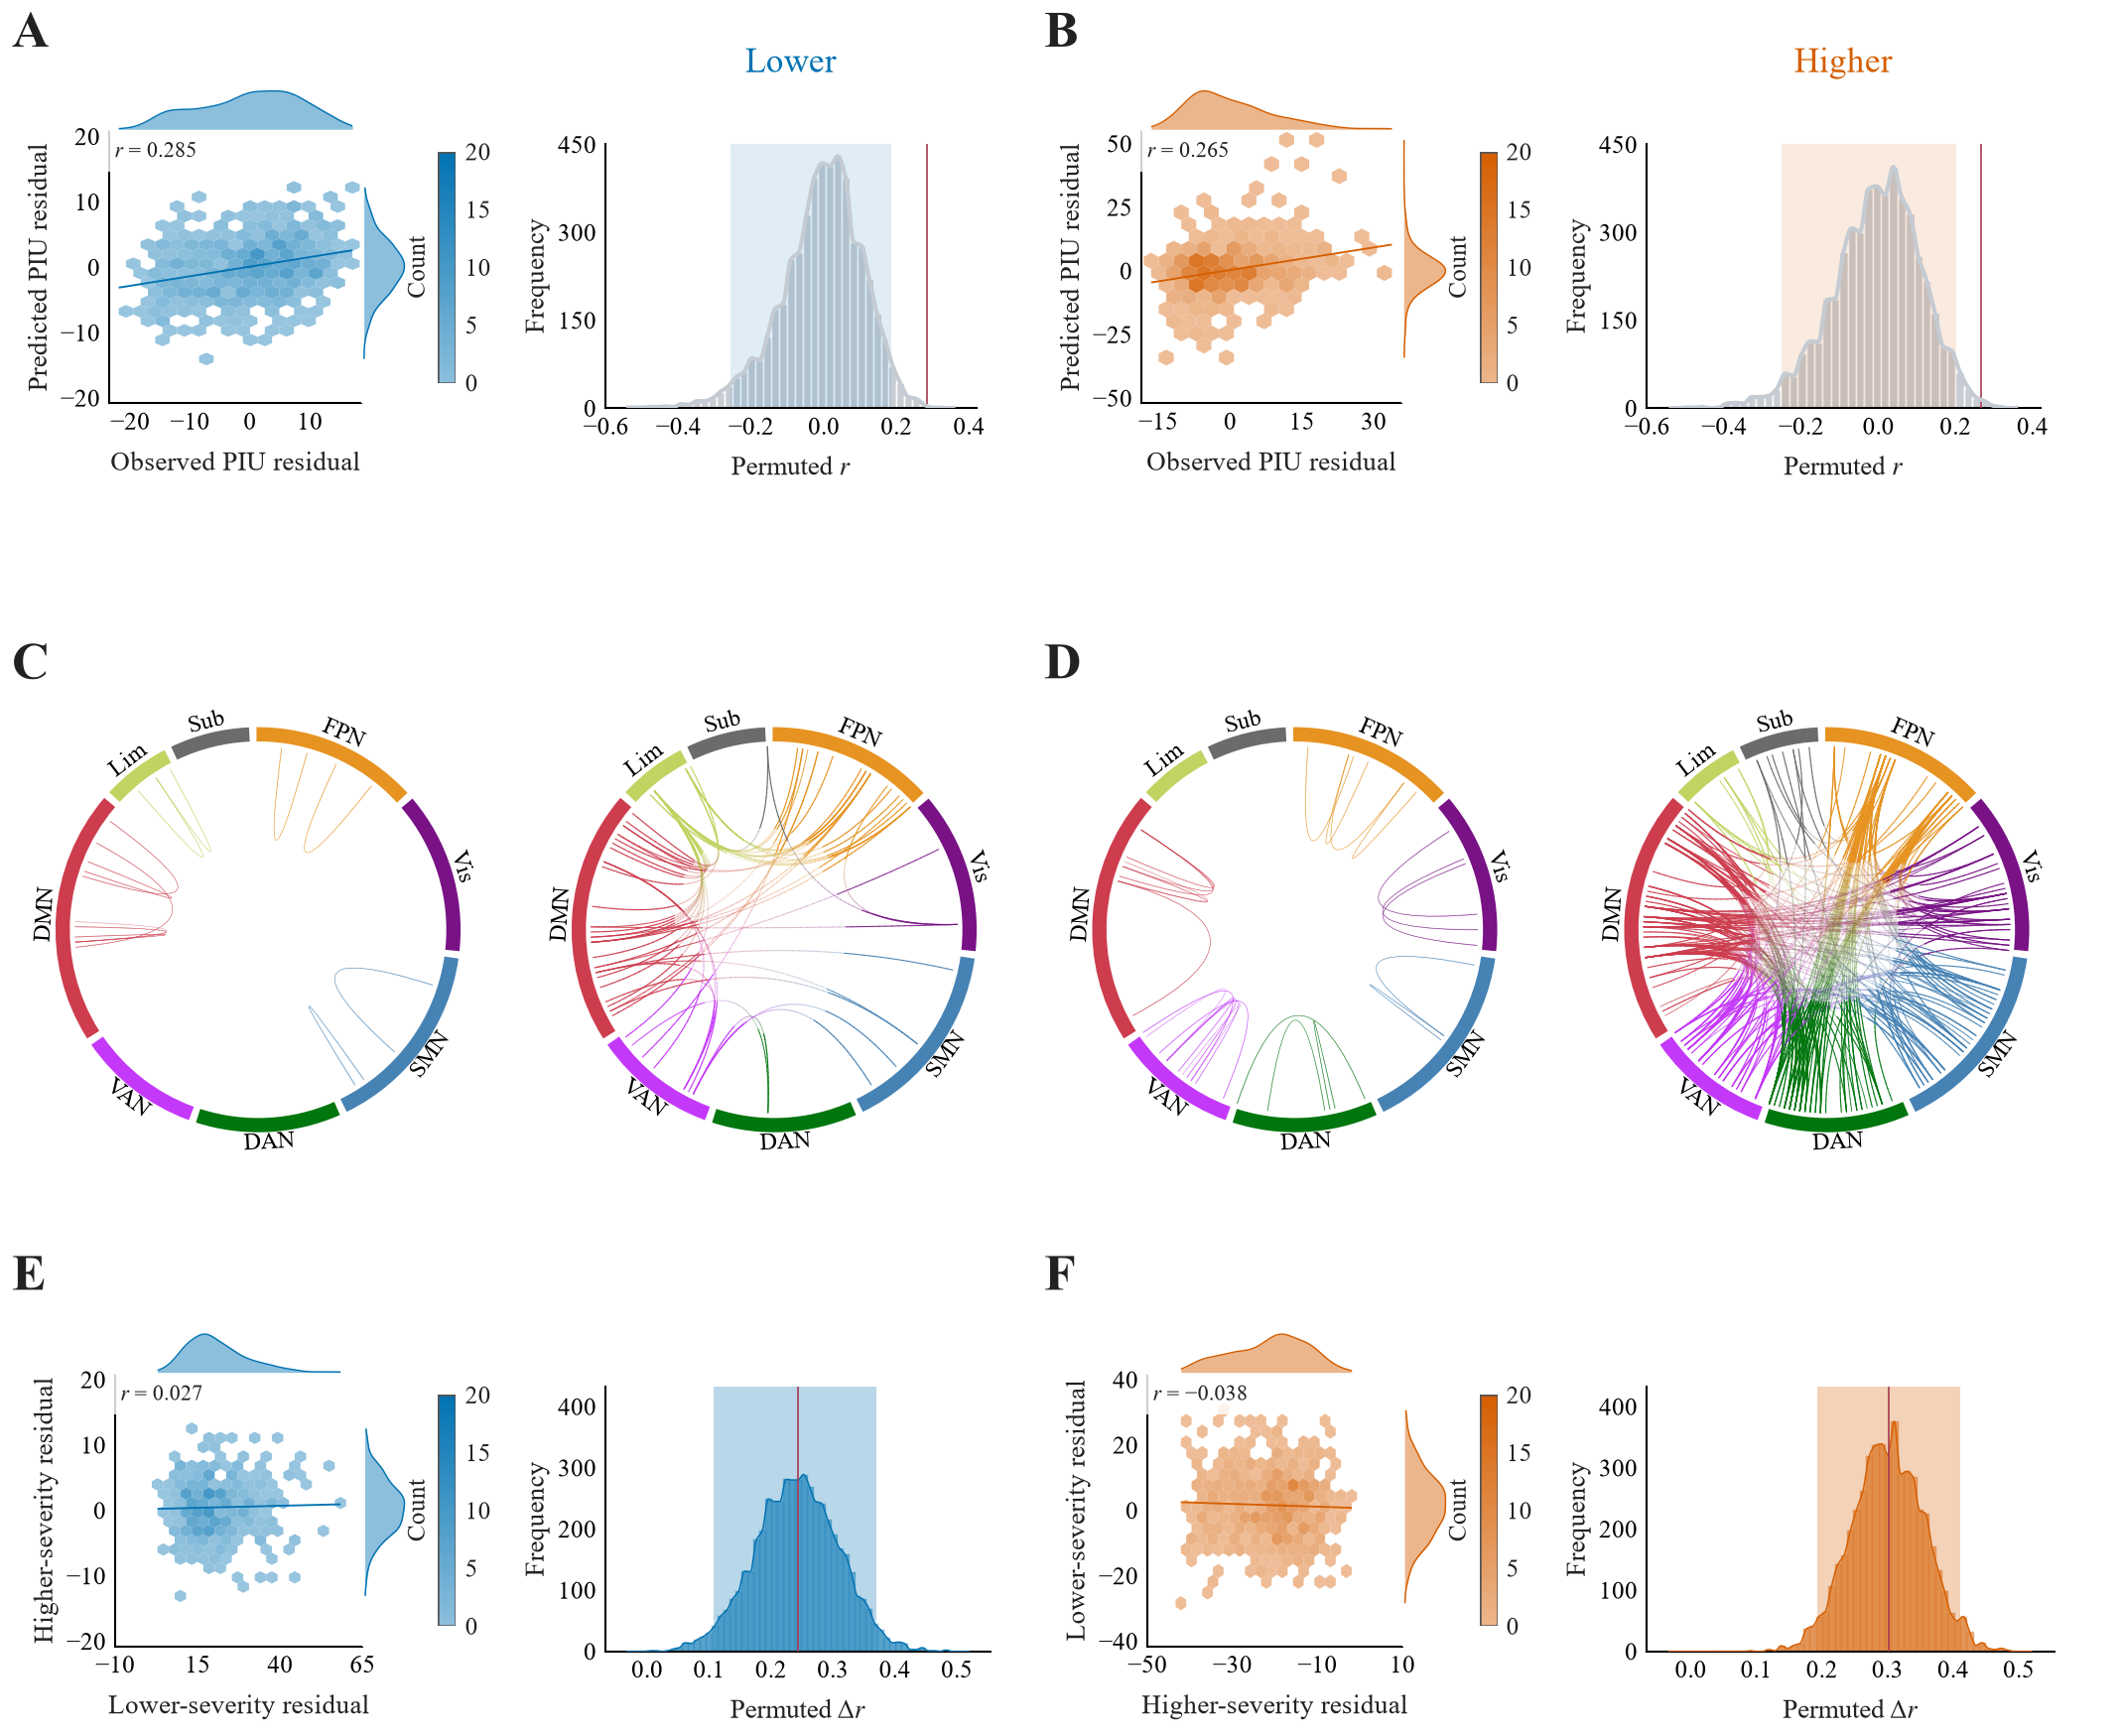


Wrote Figure 3 outputs to C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\results_figures:


In [9]:
# --- the one-shot complete canvas ---------------------------------------
out_dir = str(RESULTS_DIR)
os.makedirs(out_dir, exist_ok=True)
os.environ['FIG3_OUTPUT_DIR'] = out_dir
fig_complete = make_composite_figure(export=True, output_dir=out_dir)
plt.show()

print('\nWrote Figure 3 outputs to ' + out_dir + ':')



**Figure 3A–H | Within-range prediction and cross-range generalization.** A–D 为组内预测及其零分布与稳定边弦图；E/F 为跨范围迁移（用 source 拟合的干扰模型变换目标结局），G/H 为同一结局下 within 与 cross 相关的 paired bootstrap 差值分布。图中所有统计量均由本 notebook 计算。
